# Project-wide min50 refits — broad and Master cohorts

These are **fresh shared and grouped Pyro NUTS fits** after requiring ≥50 verified external LoLalytics games per observed matchup entering fitting/evaluation. This is distinct from earlier min50 recommendation-only filtering of the original fits.

Histories and all strictly pregame experience, WR, usage and main definitions remain unchanged. Original chronological boundaries, whole-match partitions and boundary purges are retained. Candidate recommendations require ≥50 external games for **both choices**, keep strictly better raw matchups, and allow zero prior champion/same-role play. No external smoothing or new collection occurred.

The equations, priors, group definitions and diagnostic gates are unchanged. Master rank remains absorbed in its intercept. Means, SDs, identity mappings and contrast bases are recalculated from each filtered training set. Prior validation/test outcome exposure makes this a **retrospective reanalysis**, not fresh confirmation.

Sampling ran through `min50_project_analysis.fit_models`. The cells below verify/load those completed NEW caches and display their executed results; they do not start sampling when this notebook is rerun.


In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
_min50_here=Path.cwd().resolve()
MIN50_ROOT=next(p for p in [_min50_here,*_min50_here.parents] if (p/'hlr_model/min50_project_analysis.py').is_file())
if str(MIN50_ROOT) not in sys.path:sys.path.insert(0,str(MIN50_ROOT))
from hlr_model import min50_project_analysis as min50_analysis
from hlr_model import min50_project_presentation as min50_plots
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':12,'axes.titlesize':15,'axes.labelsize':12,
    'xtick.labelsize':10,'ytick.labelsize':11,'legend.fontsize':10,'figure.facecolor':'white','axes.facecolor':'white',
    'text.color':'black','axes.labelcolor':'black','xtick.color':'black','ytick.color':'black',
    'axes.spines.top':False,'axes.spines.right':False,'savefig.transparent':False})
MIN50_REFIT_DATA=min50_plots.load(MIN50_ROOT)
print('Reporting interpreter:',sys.executable)
for cohort in ['Master','Bronze–Diamond']:
    _out,_prepared,_fits=min50_analysis.load_fits(MIN50_ROOT,cohort)
    print(cohort,'verified NEW chains:',{name:next(iter(result['samples'].values())).shape[:2] for name,result in _fits.items()})
    del _prepared,_fits


Matplotlib is building the font cache; this may take a moment.


Reporting interpreter: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/.venv-modeling-min50/bin/python


Master verified NEW chains: {'shared': (4, 1200), 'grouped': (4, 1200)}


Bronze–Diamond verified NEW chains: {'shared': (4, 1200), 'grouped': (4, 1200)}


## 1. Retained rows, fresh-fit provenance and full convergence gates

In [2]:
min50_plots.overview(MIN50_REFIT_DATA)

**These are new project-wide min50 fits**, not recommendation-only filtering of the original posteriors. Original histories and recorded experience features remain intact. Original chronological boundaries, match partitions and purges are unchanged. Pyro 1.9.2 / Torch 2.15.0; four sequential chains per model, 600 warmup + 1,200 retained draws, target acceptance .9, depth 9, one Torch thread. All four full diagnostic gates passed. Master rank is constant in its intercept; broad retains rank contrasts. Master labels are unverified legacy seeds with Global Master+ benchmarks; broad uses exact tiers and collection-time rank labels.

Bronze–Diamond NEW version: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/analyses/broad_rank_mastery_min50_v1/20261029T235057044553Z_8627ea42
Master NEW version: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/analyses/master_cohort_mastery_min50_v1/20261029T235056723818Z_f5411038


cohort,split,original_included,retained,removed,removed_percent,retained_players,retained_matches
Bronze–Diamond,train,3907,3710,197,5.04%,264,3696
Bronze–Diamond,validation,852,797,55,6.46%,145,795
Bronze–Diamond,test,928,874,54,5.82%,151,871
Master,train,5086,4462,624,12.27%,176,4187
Master,validation,1049,895,154,14.68%,124,864
Master,test,1065,943,122,11.46%,126,902


cohort,model,chains,warmup,draws_per_chain,max_Rhat,min_bulk_ESS,min_tail_ESS,divergences,min_acceptance
Bronze–Diamond,shared,4,600,1200,1.00768,2984,2136,0,1.000
Bronze–Diamond,grouped,4,600,1200,1.00651,2641,2142,0,1.000
Master,shared,4,600,1200,1.00718,3045,2116,0,1.000
Master,grouped,4,600,1200,1.00683,2412,2169,0,1.000


Stable numerical sampling does not establish predictive usefulness. Tree-depth saturation and BFMI remain unavailable from the established wrapper. Validation was evaluated before test, with parameters frozen and shared primary/grouped secondary predeclared. These outcomes were previously examined: **retrospective reanalysis, not fresh confirmation**.

## 2. EDA on retained training observations

The benchmark filter changes the fitted sample, not the historical-event pool. Corresponding rate panels share a zoom calculated from all rates and interval bounds ±5 percentage points.

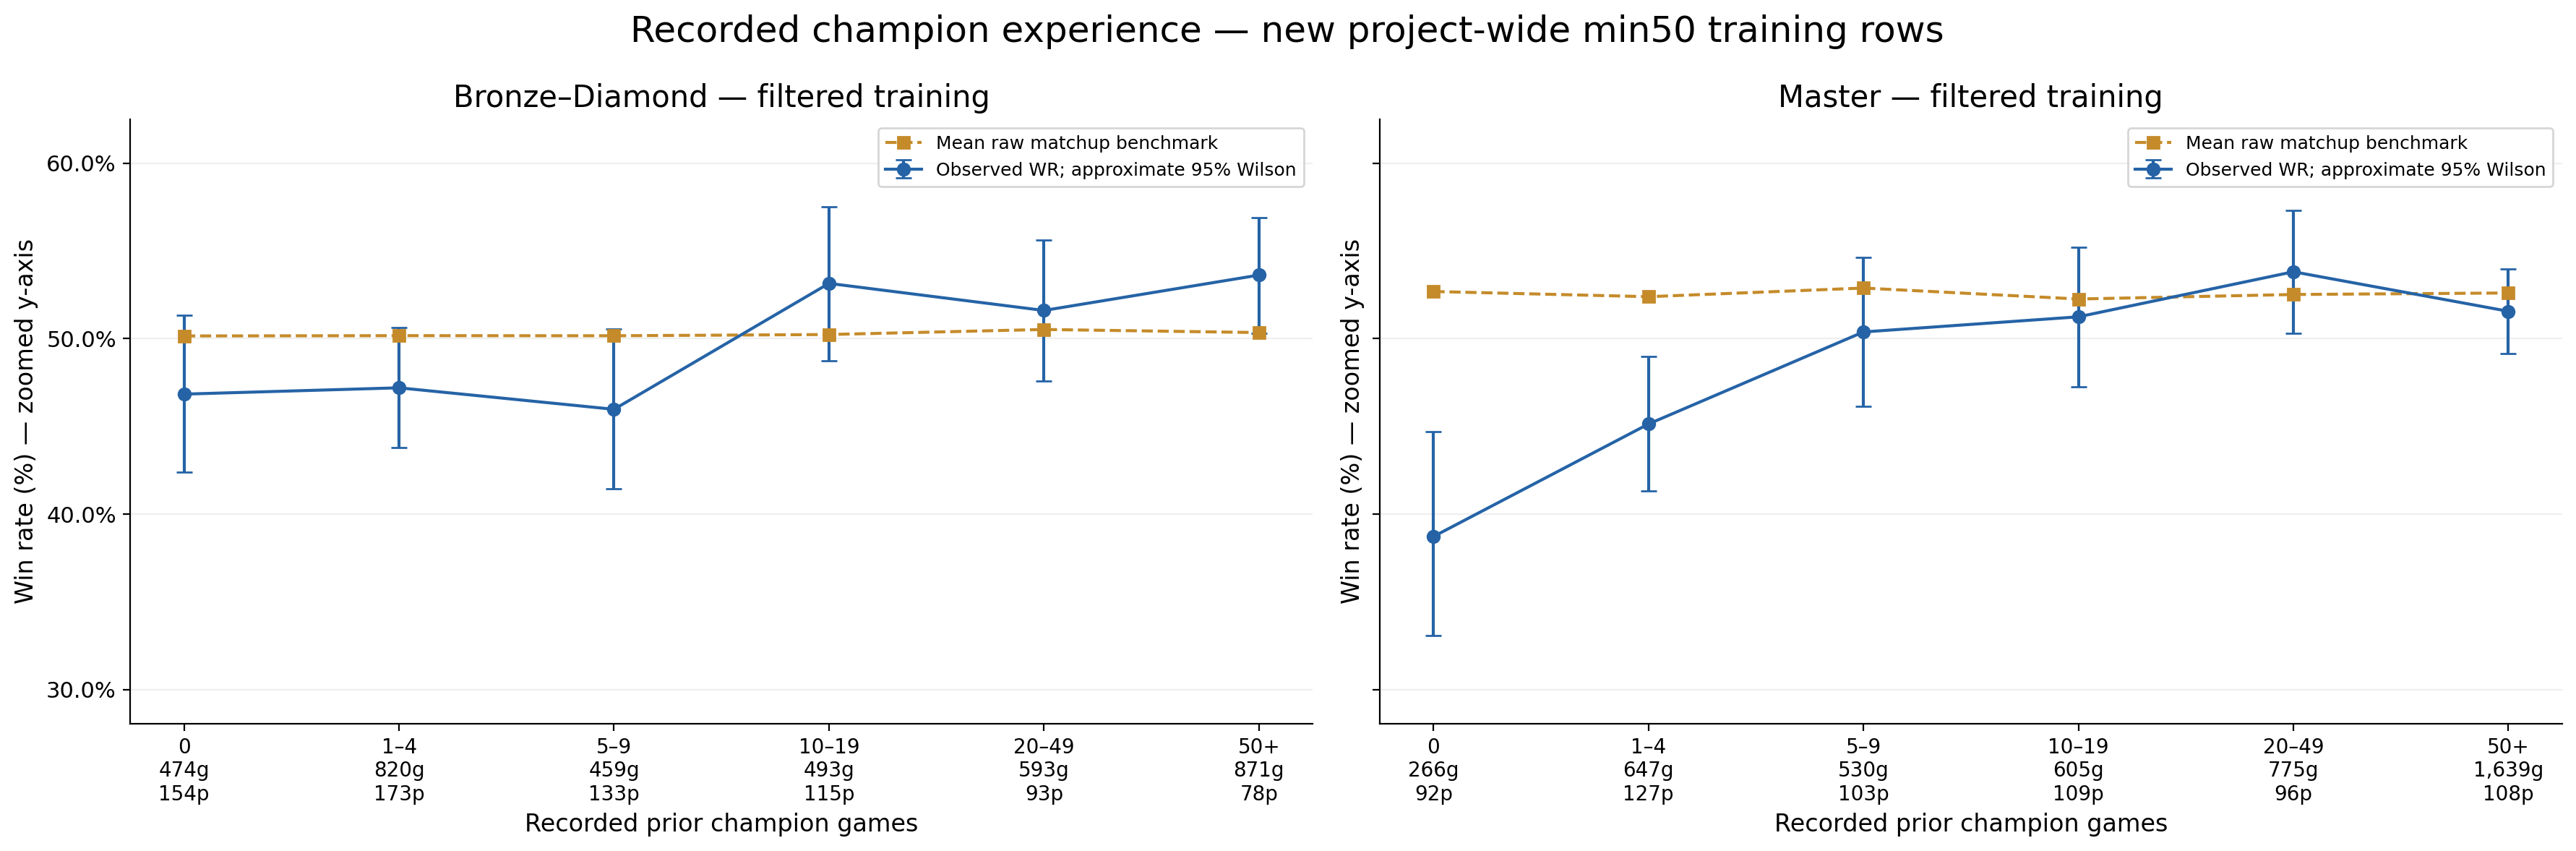

Matched observed/benchmark rows; g = likelihood player-games, p = distinct players. Wilson intervals ignore repeated-player/shared-match dependence; no benchmark interval is invented. Undefined-category exclusions: {'Bronze–Diamond': 0, 'Master': 0}. Recorded histories were not filtered. These are descriptive associations.

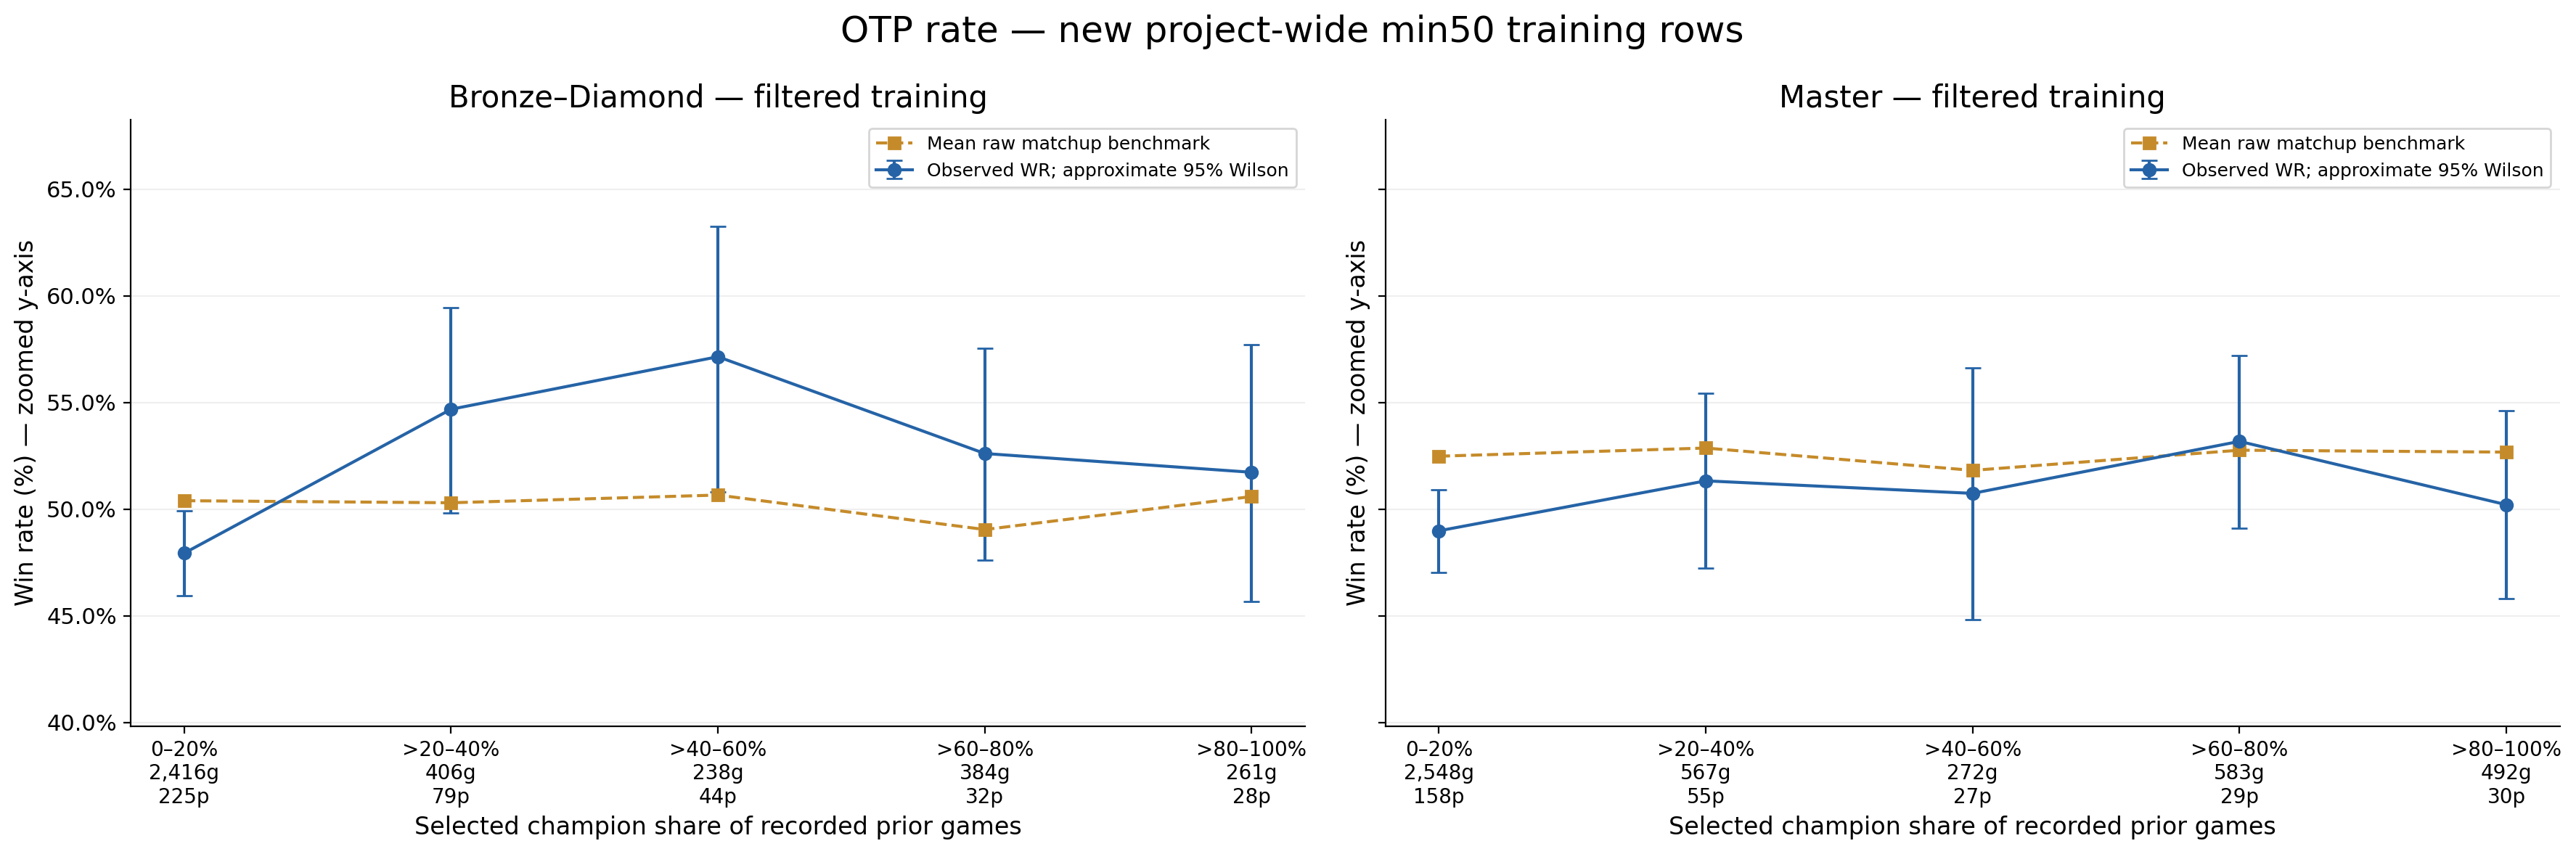

Matched observed/benchmark rows; g = likelihood player-games, p = distinct players. Wilson intervals ignore repeated-player/shared-match dependence; no benchmark interval is invented. Undefined-category exclusions: {'Bronze–Diamond': 5, 'Master': 0}. Recorded histories were not filtered. These are descriptive associations.

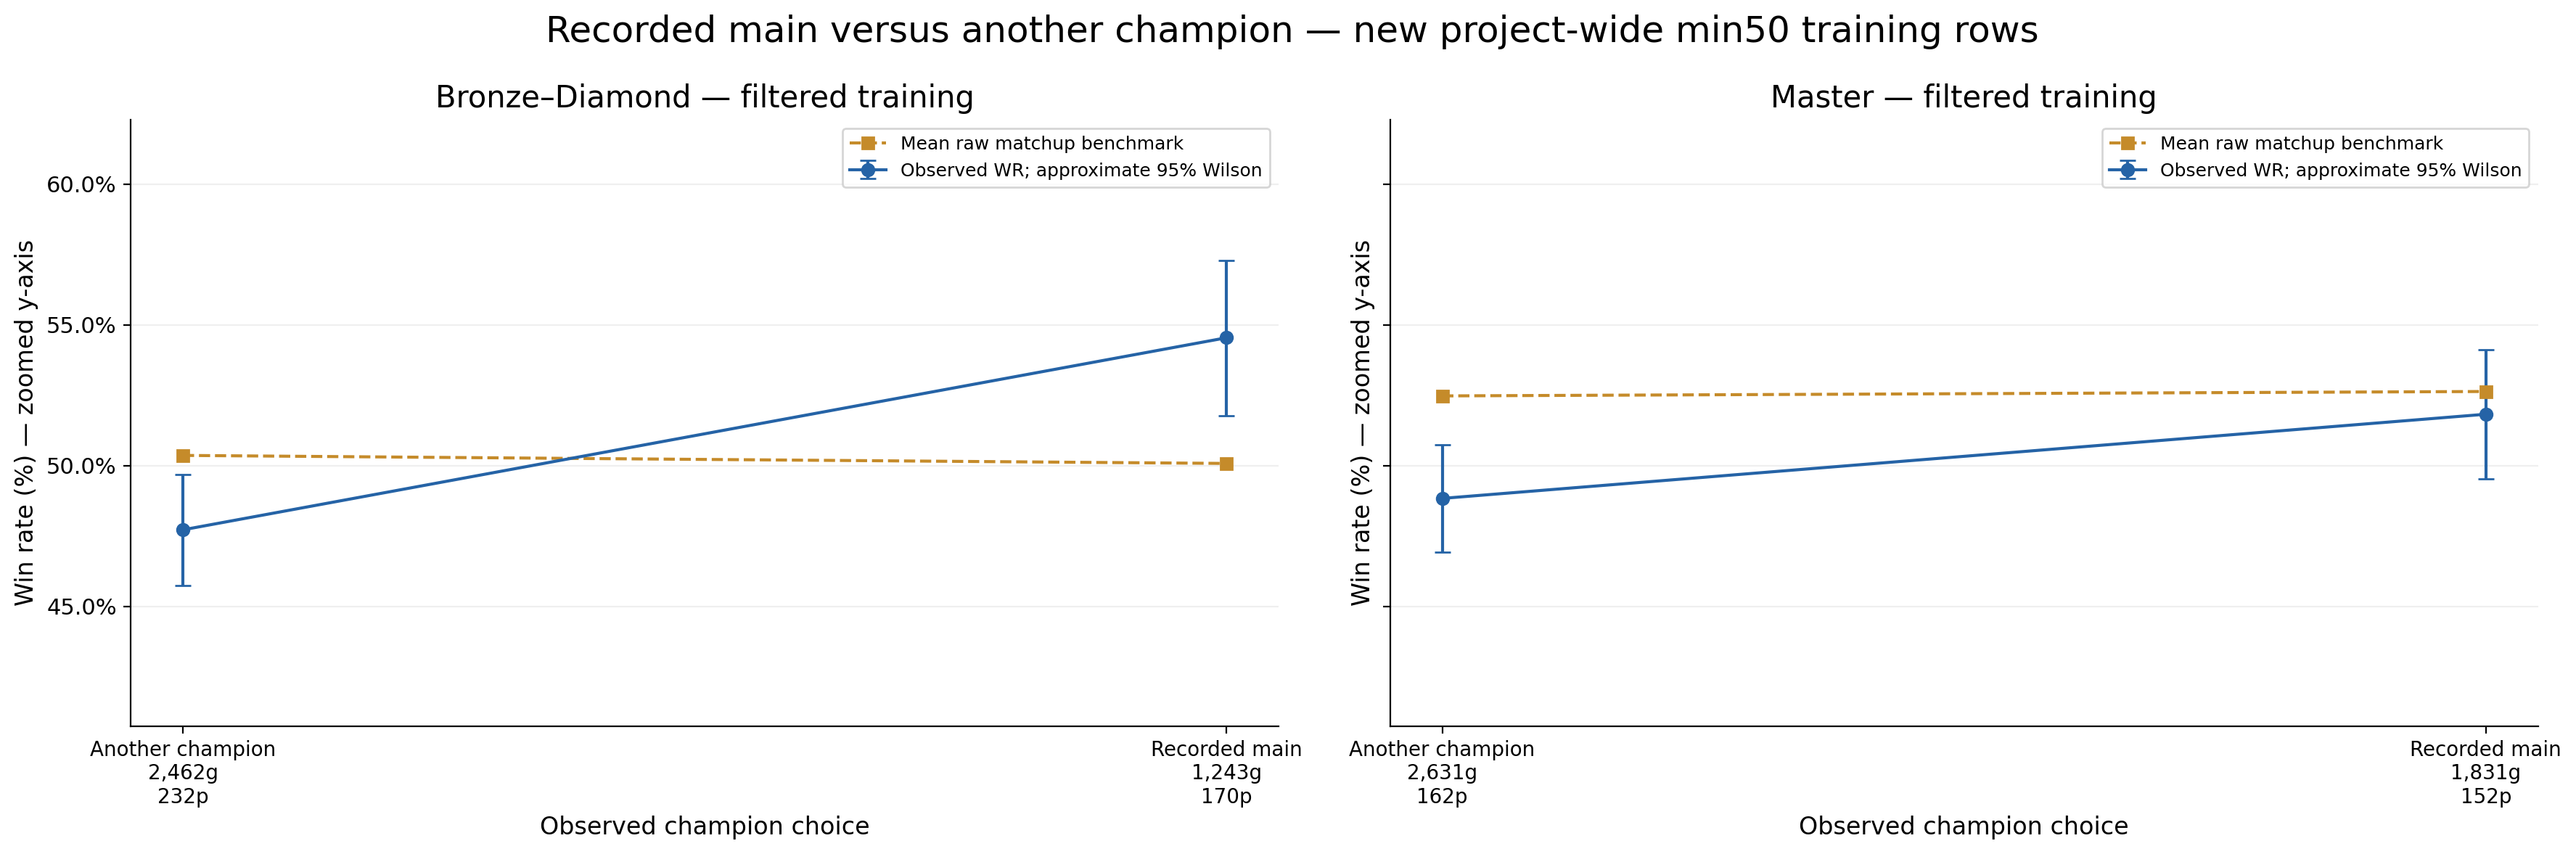

Matched observed/benchmark rows; g = likelihood player-games, p = distinct players. Wilson intervals ignore repeated-player/shared-match dependence; no benchmark interval is invented. Undefined-category exclusions: {'Bronze–Diamond': 5, 'Master': 0}. Recorded histories were not filtered. These are descriptive associations.

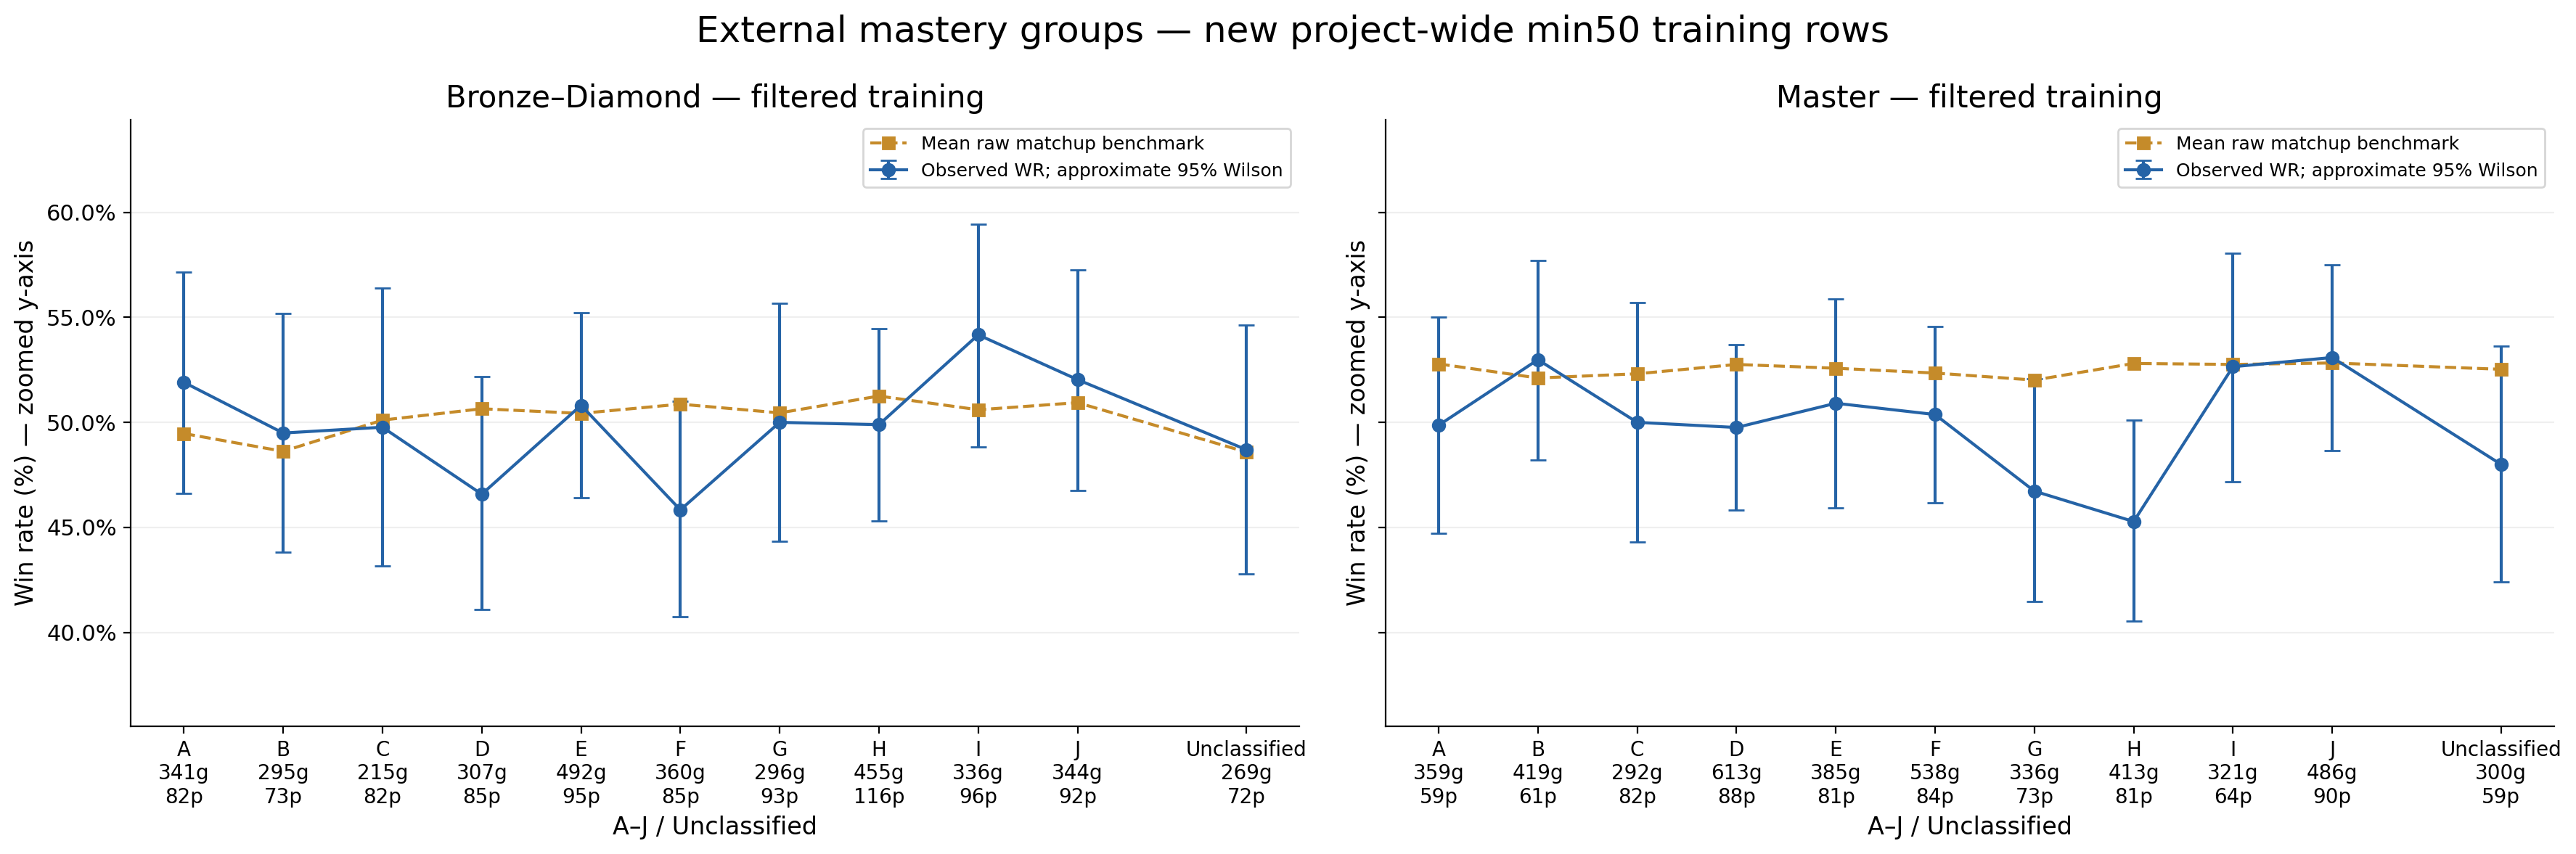

Matched observed/benchmark rows; g = likelihood player-games, p = distinct players. Wilson intervals ignore repeated-player/shared-match dependence; no benchmark interval is invented. Undefined-category exclusions: {'Bronze–Diamond': 0, 'Master': 0}. Recorded histories were not filtered. These are descriptive associations.

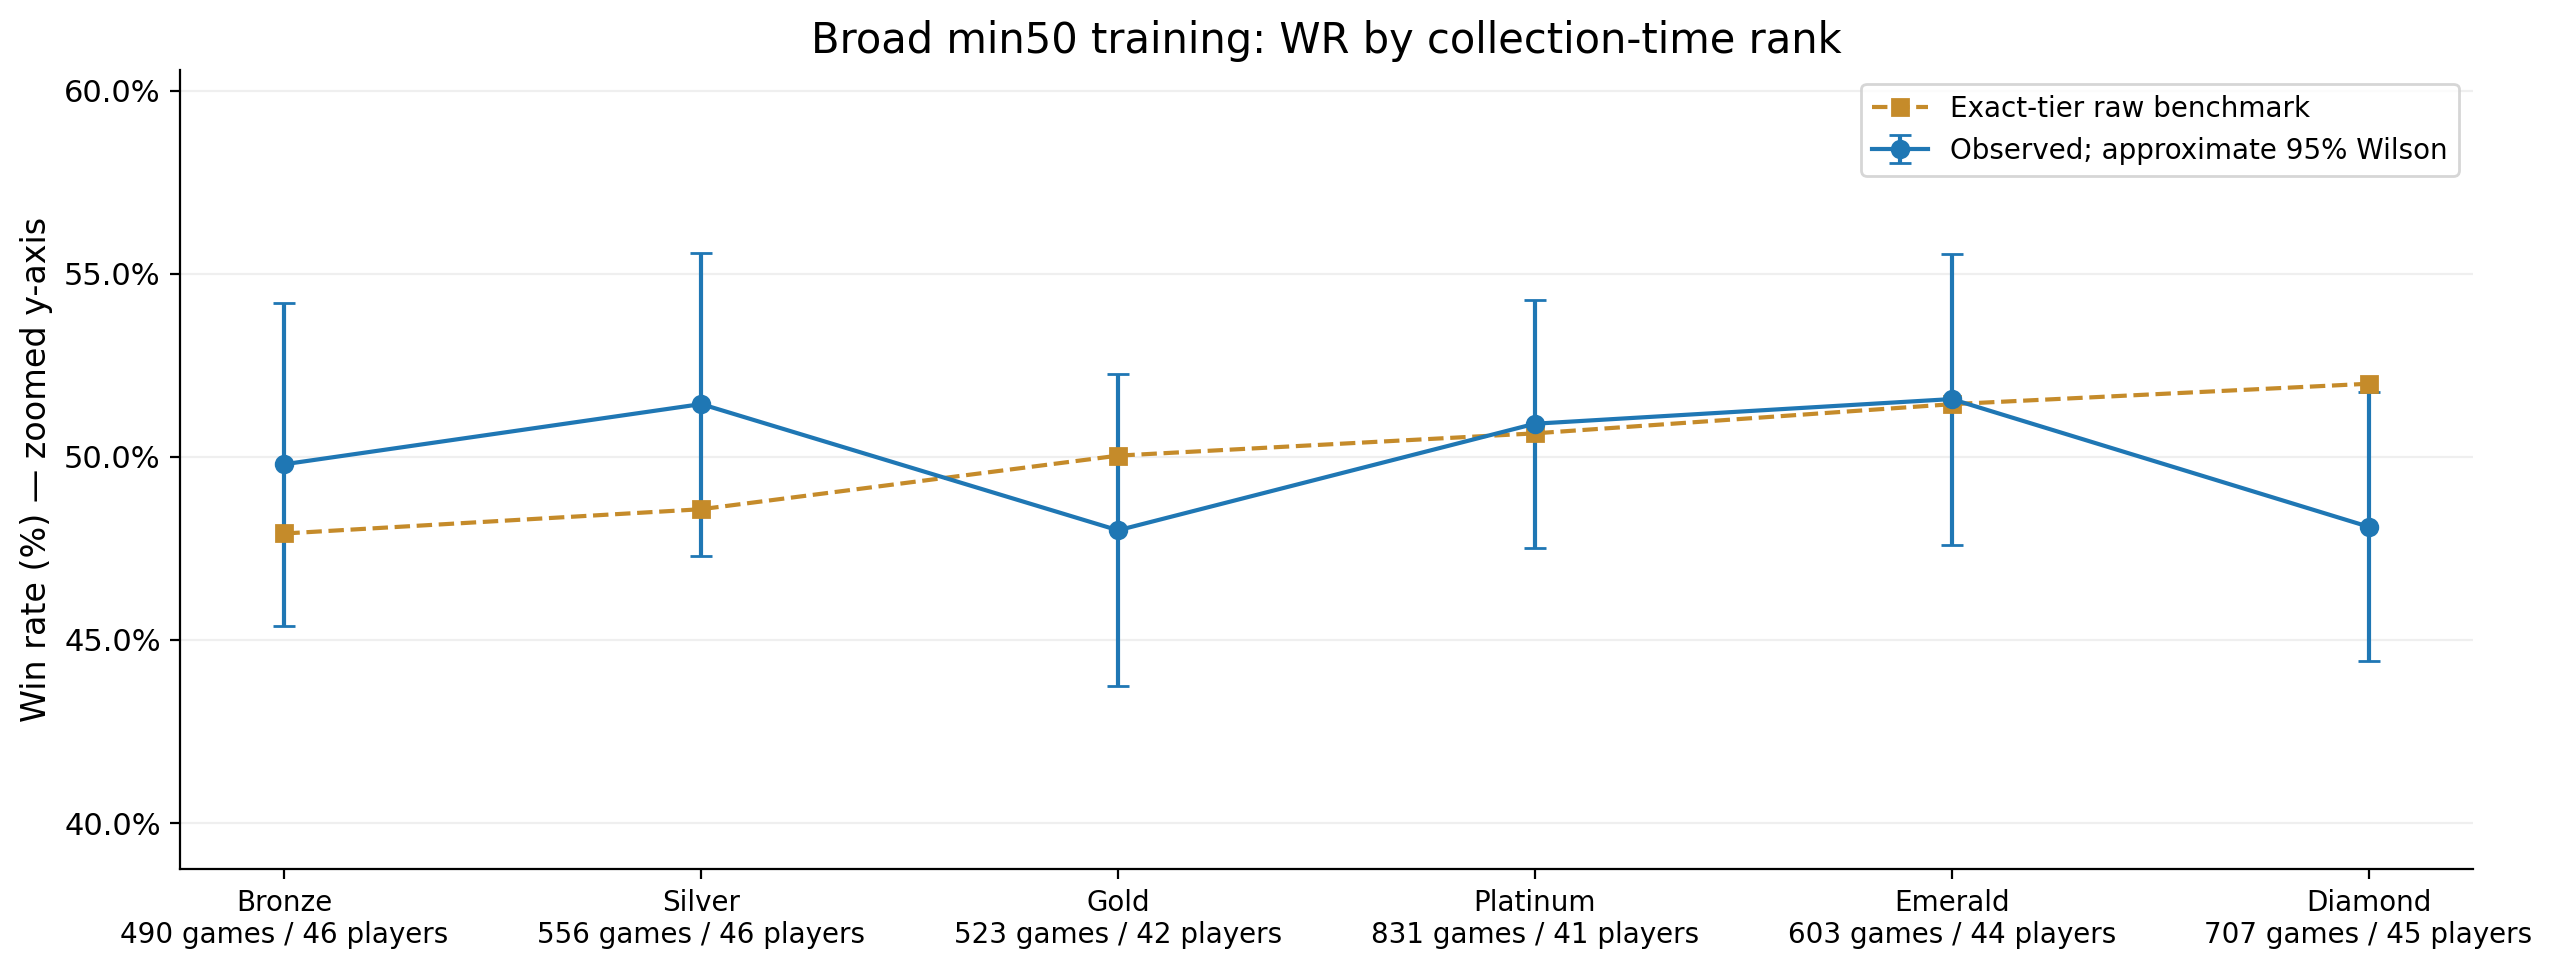

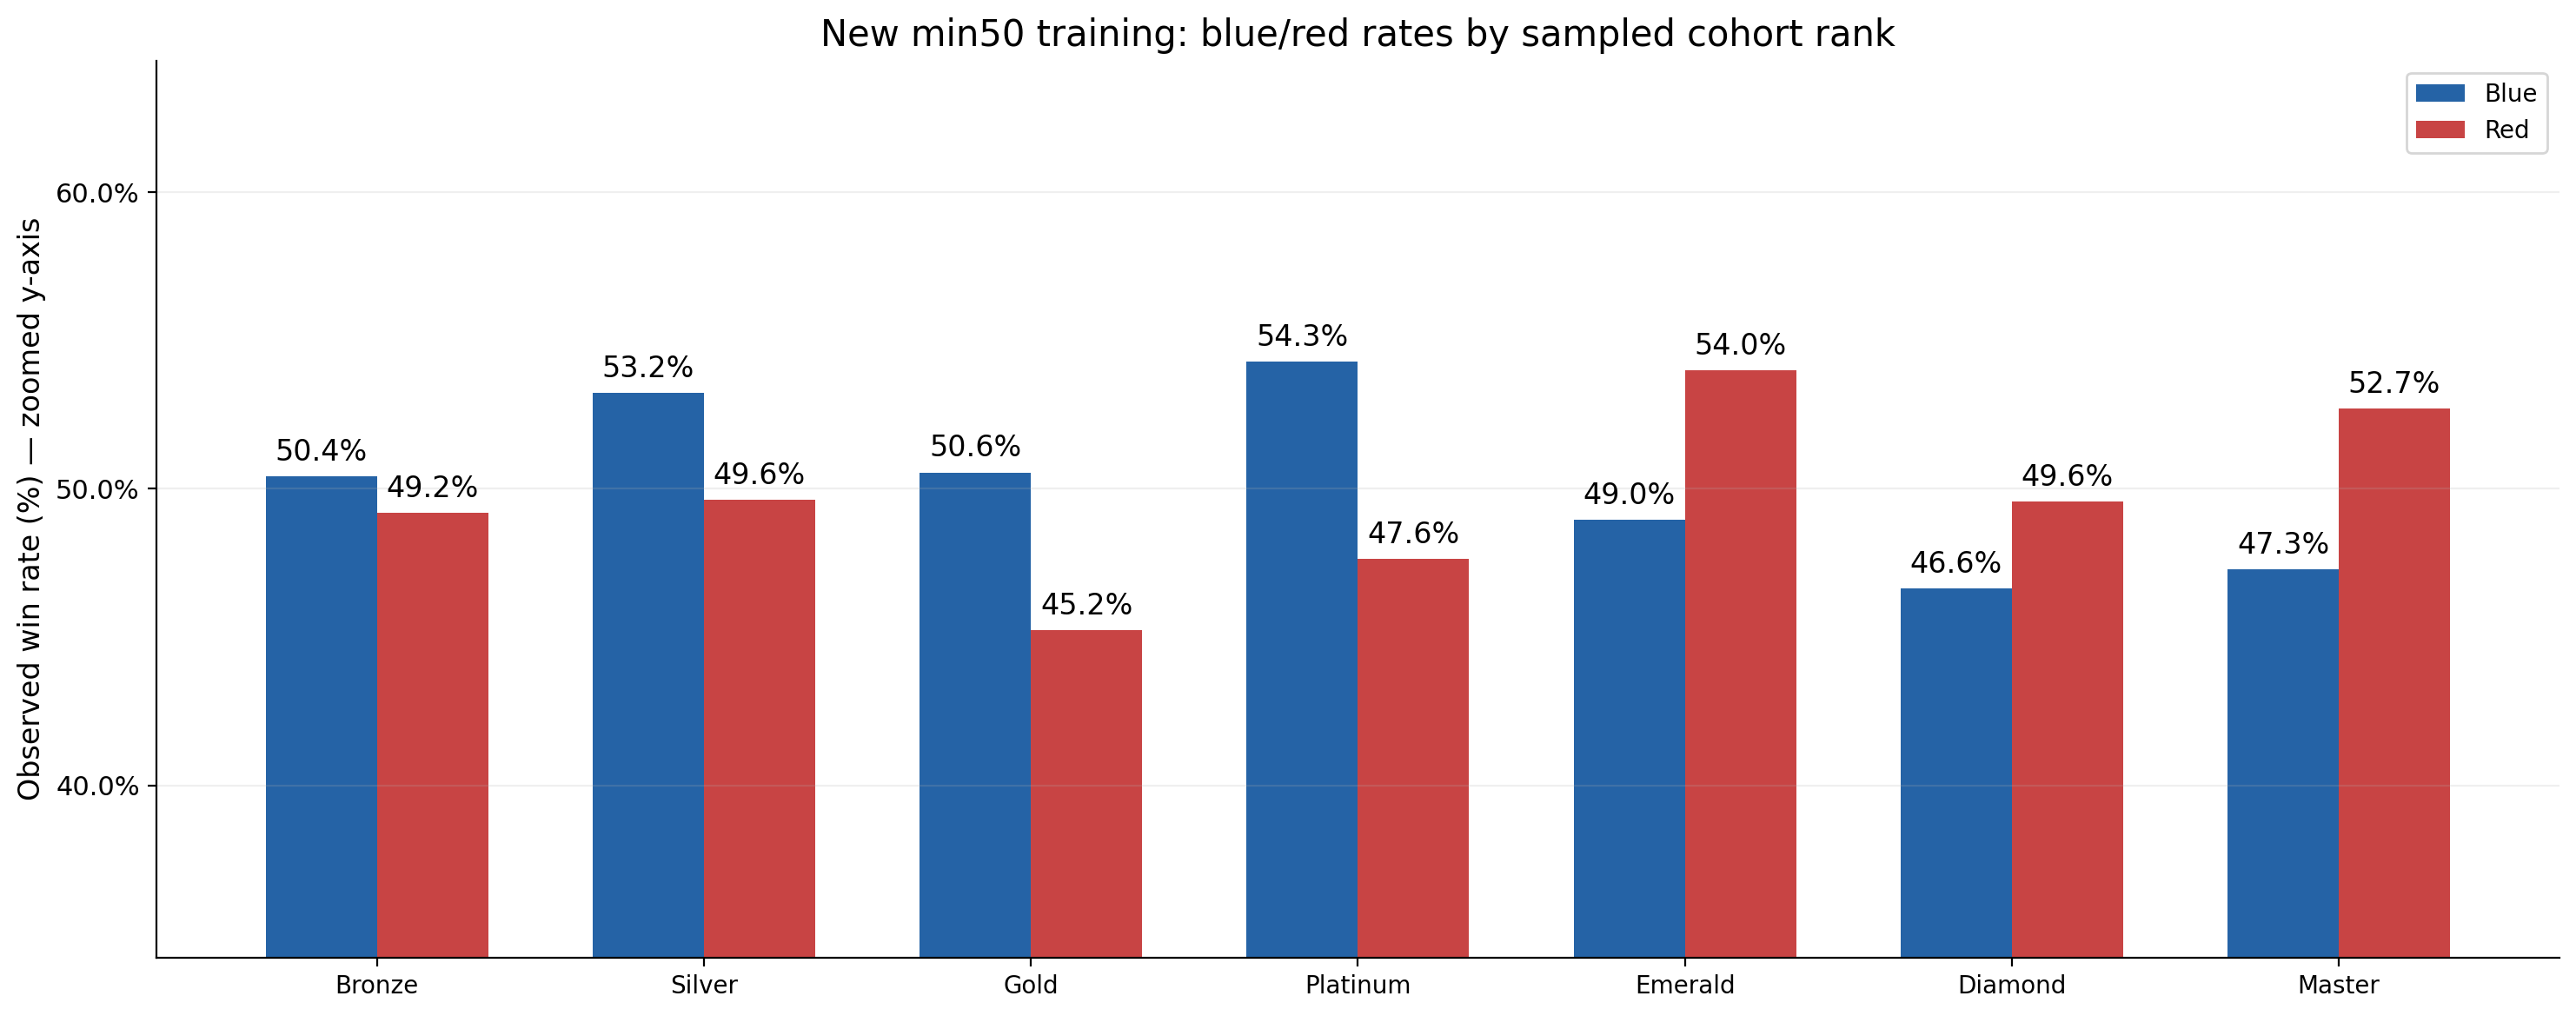

Side bars omit error bars; their shared zoom includes underlying Wilson bounds plus five percentage points. Rank labels describe sampled cohorts; Master uses unverified legacy seed labels. No causal side or rank effect is established.

In [3]:
min50_plots.eda(MIN50_REFIT_DATA)

## 3. Primary shared-model estimates and new training standardization

In [4]:
min50_plots.parameters(MIN50_REFIT_DATA,grouped=False)

parameter,units,median,low_95,high_95,probability_positive
Intercept,Log-odds; centered continuous covariates; n=0; top/reference rank; zero identity effects,-0.179,-0.448,0.074,0.081
Raw matchup,Log-odds per filtered-training SD,0.120,0.046,0.191,0.999
log(1 + prior total games),Log-odds per filtered-training SD,-0.057,-0.133,0.018,0.070
"Historical champion WR Beta(1,1)",Log-odds per filtered-training SD,0.027,-0.041,0.092,0.772
Raw matchup: +2 percentage points,Log-odds per +0.02 raw matchup probability,0.060,0.023,0.096,0.999
jungle versus top,Log-odds contrast,0.070,-0.150,0.299,0.728
mid versus top,Log-odds contrast,0.137,-0.092,0.367,0.884
adc versus top,Log-odds contrast,0.068,-0.155,0.294,0.725
support versus top,Log-odds contrast,0.166,-0.064,0.387,0.925
SILVER versus Bronze,Log-odds contrast,0.037,-0.223,0.304,0.610


parameter,units,median,low_95,high_95,probability_positive
Intercept,Log-odds; centered continuous covariates; n=0; top/reference rank; zero identity effects,-0.303,-0.587,-0.045,0.011
Raw matchup,Log-odds per filtered-training SD,0.148,0.091,0.207,1.000
log(1 + prior total games),Log-odds per filtered-training SD,-0.033,-0.100,0.034,0.172
"Historical champion WR Beta(1,1)",Log-odds per filtered-training SD,0.010,-0.052,0.074,0.618
Raw matchup: +2 percentage points,Log-odds per +0.02 raw matchup probability,0.077,0.047,0.108,1.000
jungle versus top,Log-odds contrast,0.008,-0.204,0.218,0.531
mid versus top,Log-odds contrast,-0.169,-0.372,0.031,0.050
adc versus top,Log-odds contrast,-0.064,-0.271,0.143,0.282
support versus top,Log-odds contrast,-0.177,-0.396,0.046,0.059
Experience amplitude,Asymptotic log-odds; common amplitude,0.539,0.291,0.787,1.000


cohort,predictor,training_mean,training_SD
Bronze–Diamond,matchup_probability,0.502697,0.039840
Bronze–Diamond,log_total,4.794915,0.841635
Bronze–Diamond,historical_wr_beta11,0.521035,0.115500
Master,matchup_probability,0.525443,0.038341
Master,log_total,5.226919,0.228027
Master,historical_wr_beta11,0.538905,0.105468


Coefficients are log-odds, not win-probability percentage points. The common +2 raw matchup pp row equals β × .02 / the NEW training SD. Experience is b × n/(n+k); n is recorded prior champion games, and k is half-saturation in recorded games. k and SDs are exponentiated from their log parameters, with blank sign probabilities; posterior sign probabilities are not p-values. Shared uses one experience amplitude; grouped totals add the shared amplitude and the reconstructed zero-sum group deviation. The original priors/equations/group definitions are unchanged. No A–J ordering is imposed.

## 4. Frozen validation first, then previously examined test outcomes

model,mode,split,rows,players,matches,log_loss,brier,roc_auc,equal_player_log_loss,equal_player_brier,cohort
shared,general,validation,797,145,795,0.688954,0.247916,0.549080,0.688937,0.247907,Bronze–Diamond
shared,personalized,validation,797,145,795,0.689746,0.248314,0.541648,0.689418,0.248151,Bronze–Diamond
grouped,general,validation,797,145,795,0.689985,0.248428,0.542788,0.688865,0.247871,Bronze–Diamond
grouped,personalized,validation,797,145,795,0.690648,0.248763,0.536327,0.689257,0.248071,Bronze–Diamond
training_prevalence,benchmark,validation,797,145,795,0.693147,0.250000,0.500000,0.693147,0.250000,Bronze–Diamond
raw_matchup,benchmark,validation,797,145,795,0.694214,0.250535,0.506764,0.697709,0.252269,Bronze–Diamond
training_prevalence,benchmark,validation,895,124,864,0.693083,0.249968,0.500000,0.693007,0.249930,Master
raw_matchup,benchmark,validation,895,124,864,0.690253,0.248545,0.536175,0.690931,0.248888,Master
shared,general,validation,895,124,864,0.695826,0.251286,0.523419,0.697093,0.251907,Master
shared,personalized,validation,895,124,864,0.695542,0.251151,0.523064,0.696664,0.251689,Master


cohort,model,mode,rows,players,matches,log_loss,brier,roc_auc,equal_player_log_loss,equal_player_brier
Bronze–Diamond,shared,general,874,151,871,0.69501,0.25093,0.50758,0.69009,0.24850
Bronze–Diamond,shared,personalized,874,151,871,0.69479,0.25082,0.51064,0.69030,0.24860
Bronze–Diamond,grouped,general,874,151,871,0.69492,0.25089,0.50833,0.69052,0.24872
Bronze–Diamond,grouped,personalized,874,151,871,0.69475,0.25080,0.51052,0.69086,0.24888
Bronze–Diamond,training_prevalence,benchmark,874,151,871,0.69315,0.25000,0.50000,0.69315,0.25000
Bronze–Diamond,raw_matchup,benchmark,874,151,871,0.69330,0.25009,0.51305,0.69193,0.24943
Master,training_prevalence,benchmark,943,126,902,0.69312,0.24998,0.50000,0.69307,0.24996
Master,raw_matchup,benchmark,943,126,902,0.68825,0.24759,0.54426,0.69052,0.24873
Master,shared,general,943,126,902,0.68907,0.24798,0.55176,0.69923,0.25303
Master,shared,personalized,943,126,902,0.68947,0.24819,0.54660,0.69813,0.25249


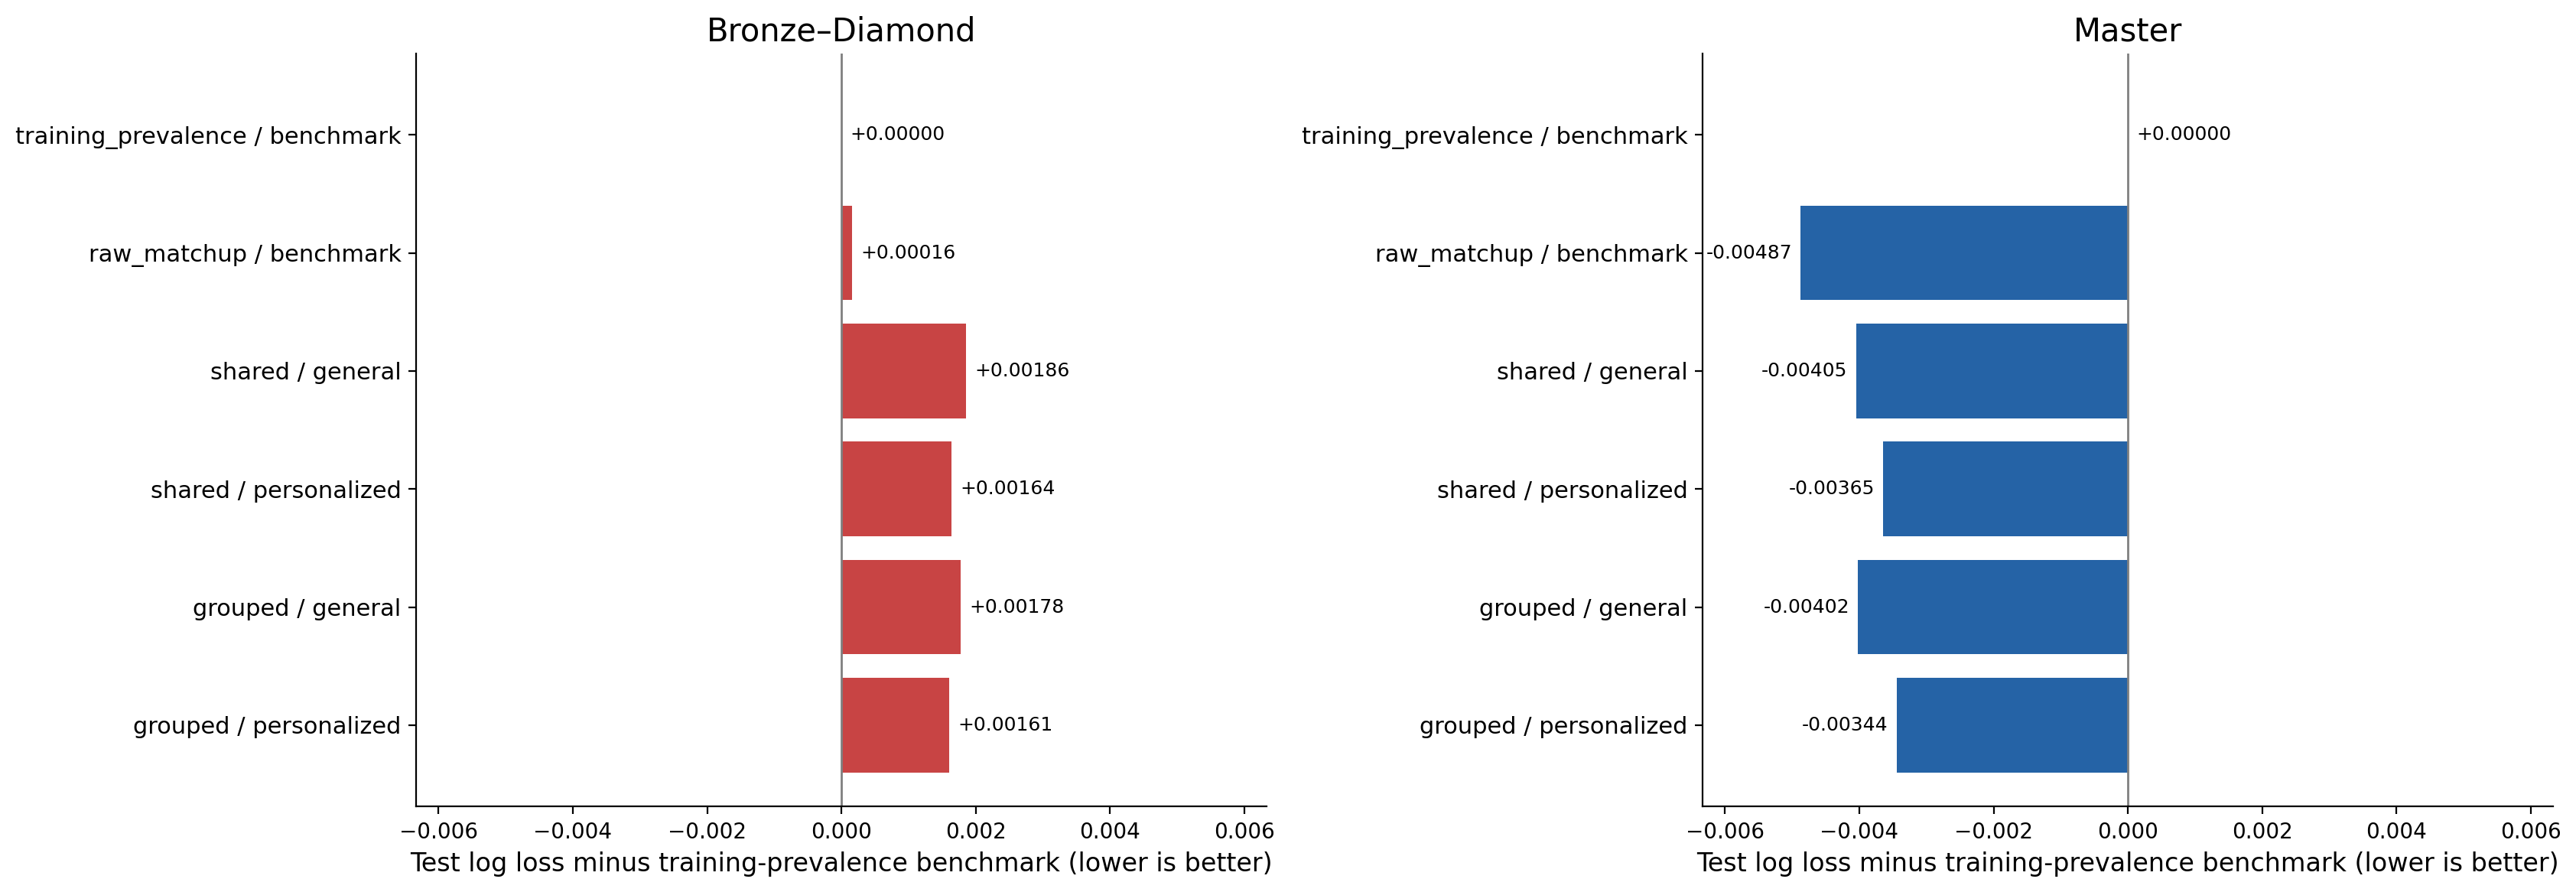

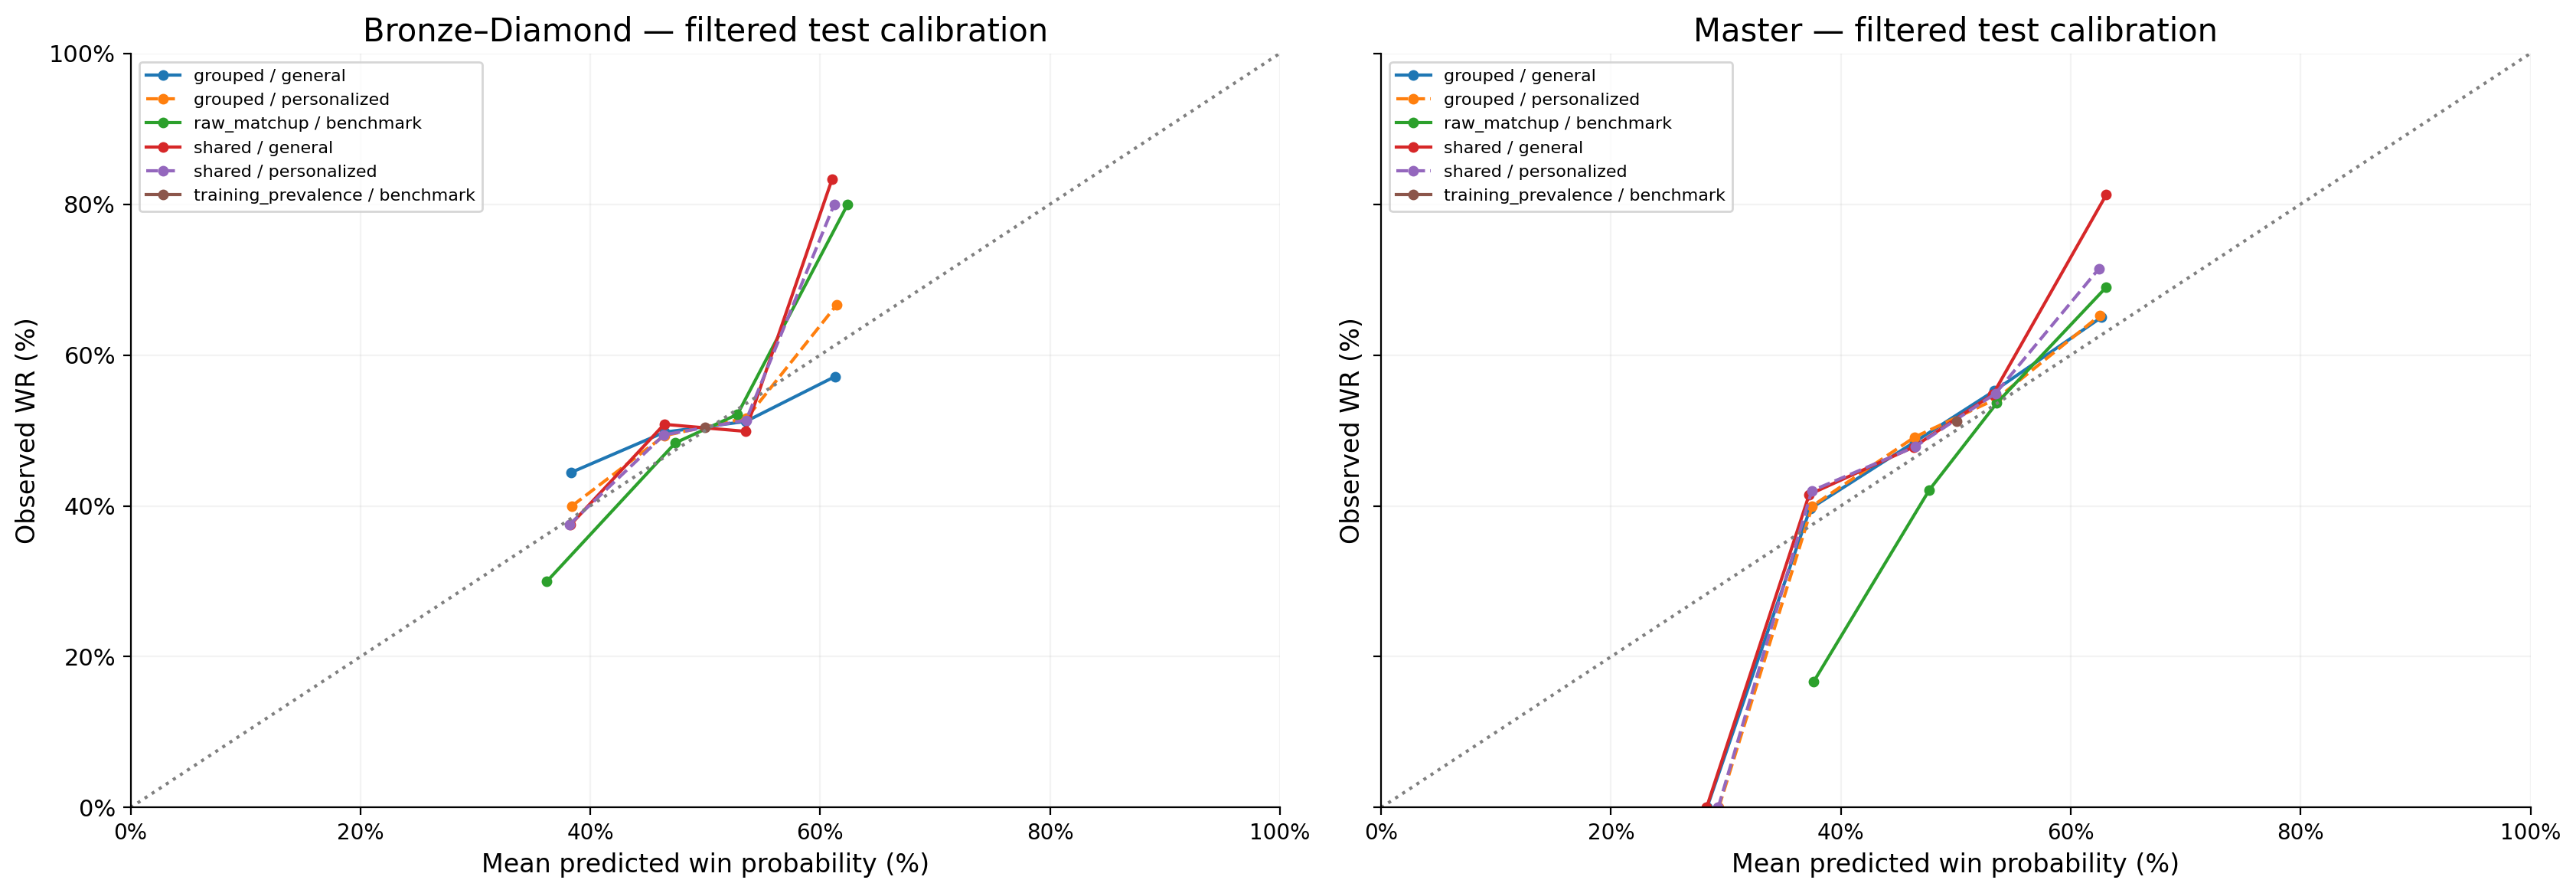

These held-out outcomes were previously examined. Test was evaluated only after validation, with fitted parameters and the predeclared shared/grouped roles frozen. No test tuning occurred. Calibration retains 0–100% axes; sparse extreme bins are unstable. Loss/AUC/equal-player values measure prediction, not switching benefits.

In [5]:
min50_plots.white_table(__import__('pandas').concat([d['metrics'].loc[d['metrics'].split.eq('validation')] for d in MIN50_REFIT_DATA.values()],ignore_index=True),'Filtered validation: models and fixed benchmarks on identical rows')
min50_plots.predictive_results(MIN50_REFIT_DATA)

## 5. Conditional experience curves and grouped secondary specification

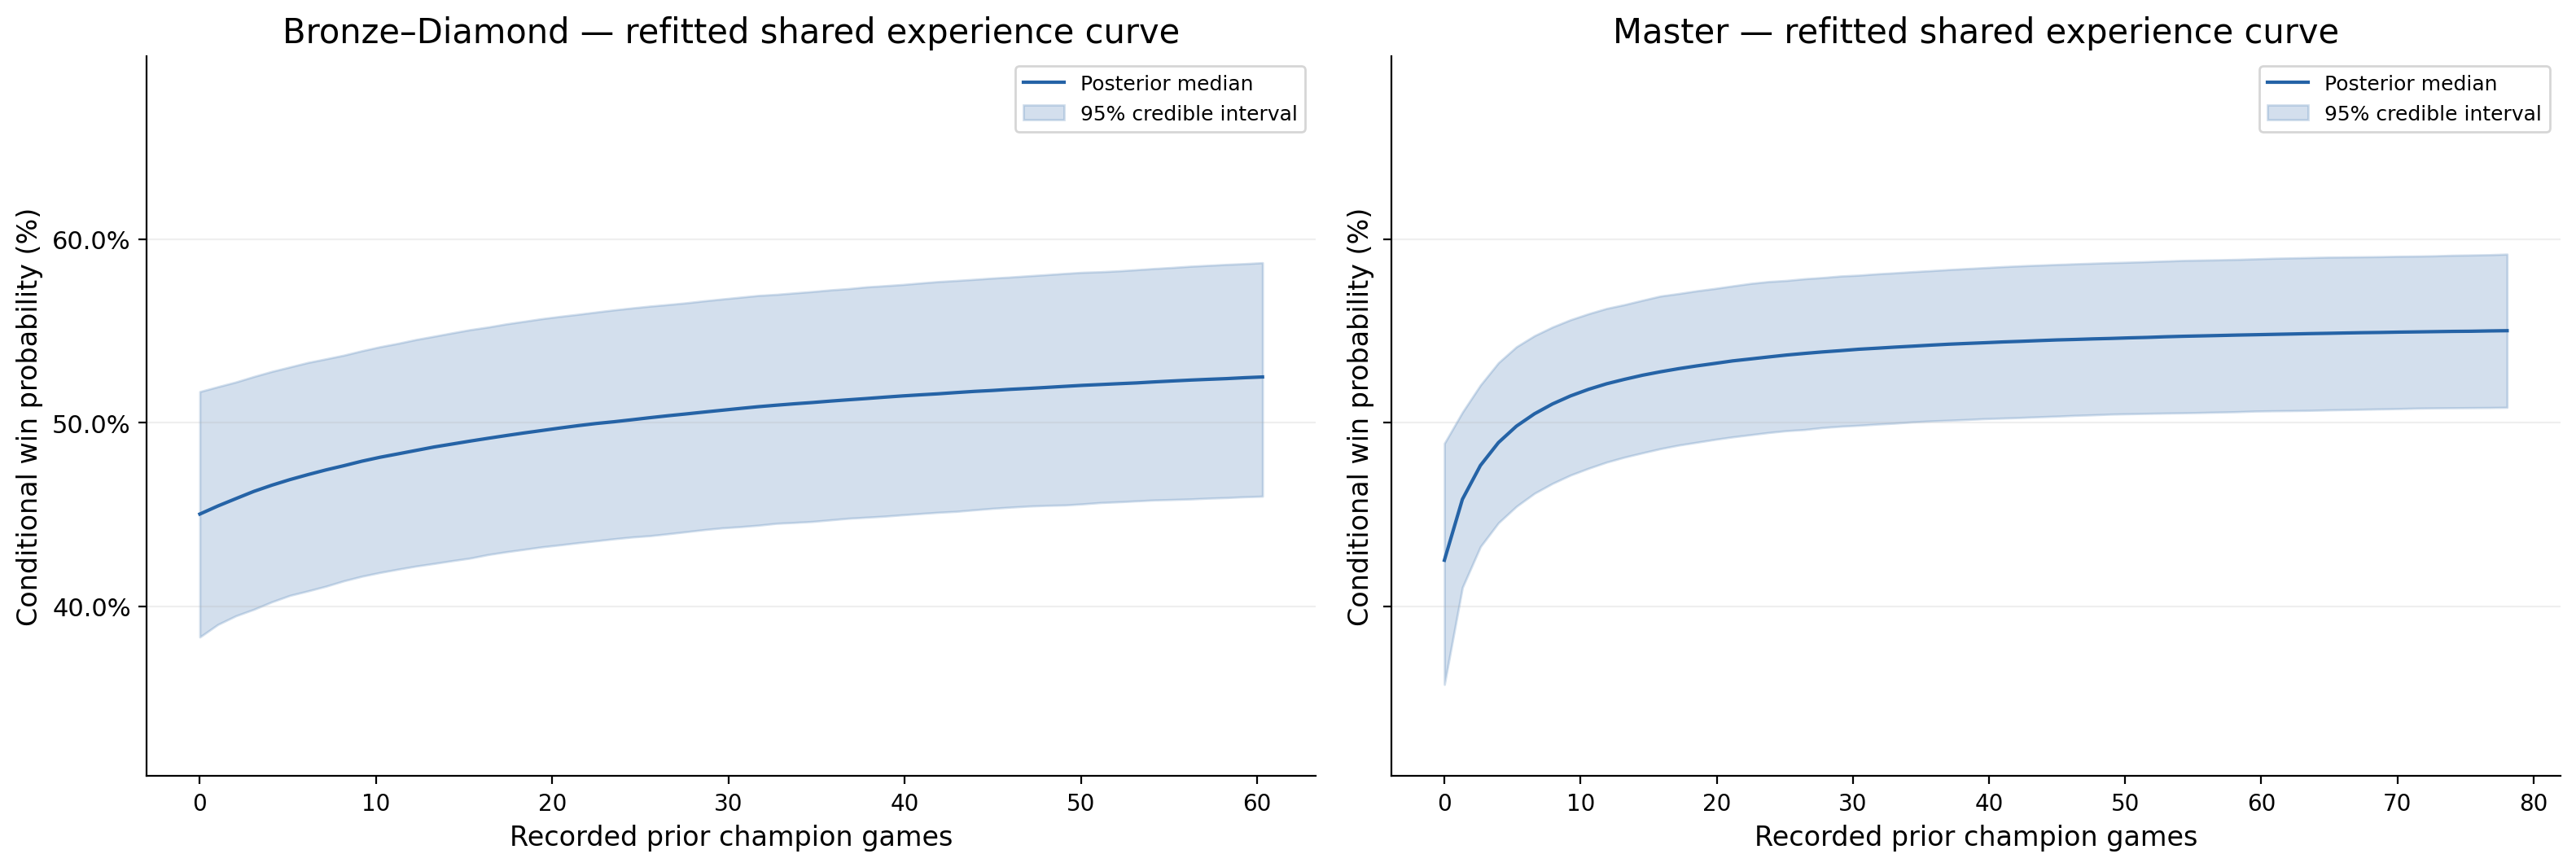

cohort,matchup_percent,historical_WR_percent,total_prior_games,role,rank,max_displayed_experience
Bronze–Diamond,50.500000,51.020408,174.000000,Top,Bronze,60.300000
Master,52.570000,54.166667,186.000000,Top,Master constant,78.050000


Conditional reference-player illustrations, not population averages or total causal benefits of practice. Curves control historical champion WR and other covariates. Displayed experience stops at saved training-support/context caps; counts never exceed total prior games. Shared/grouped curve panels use one common zoom including all pointwise credible bands.

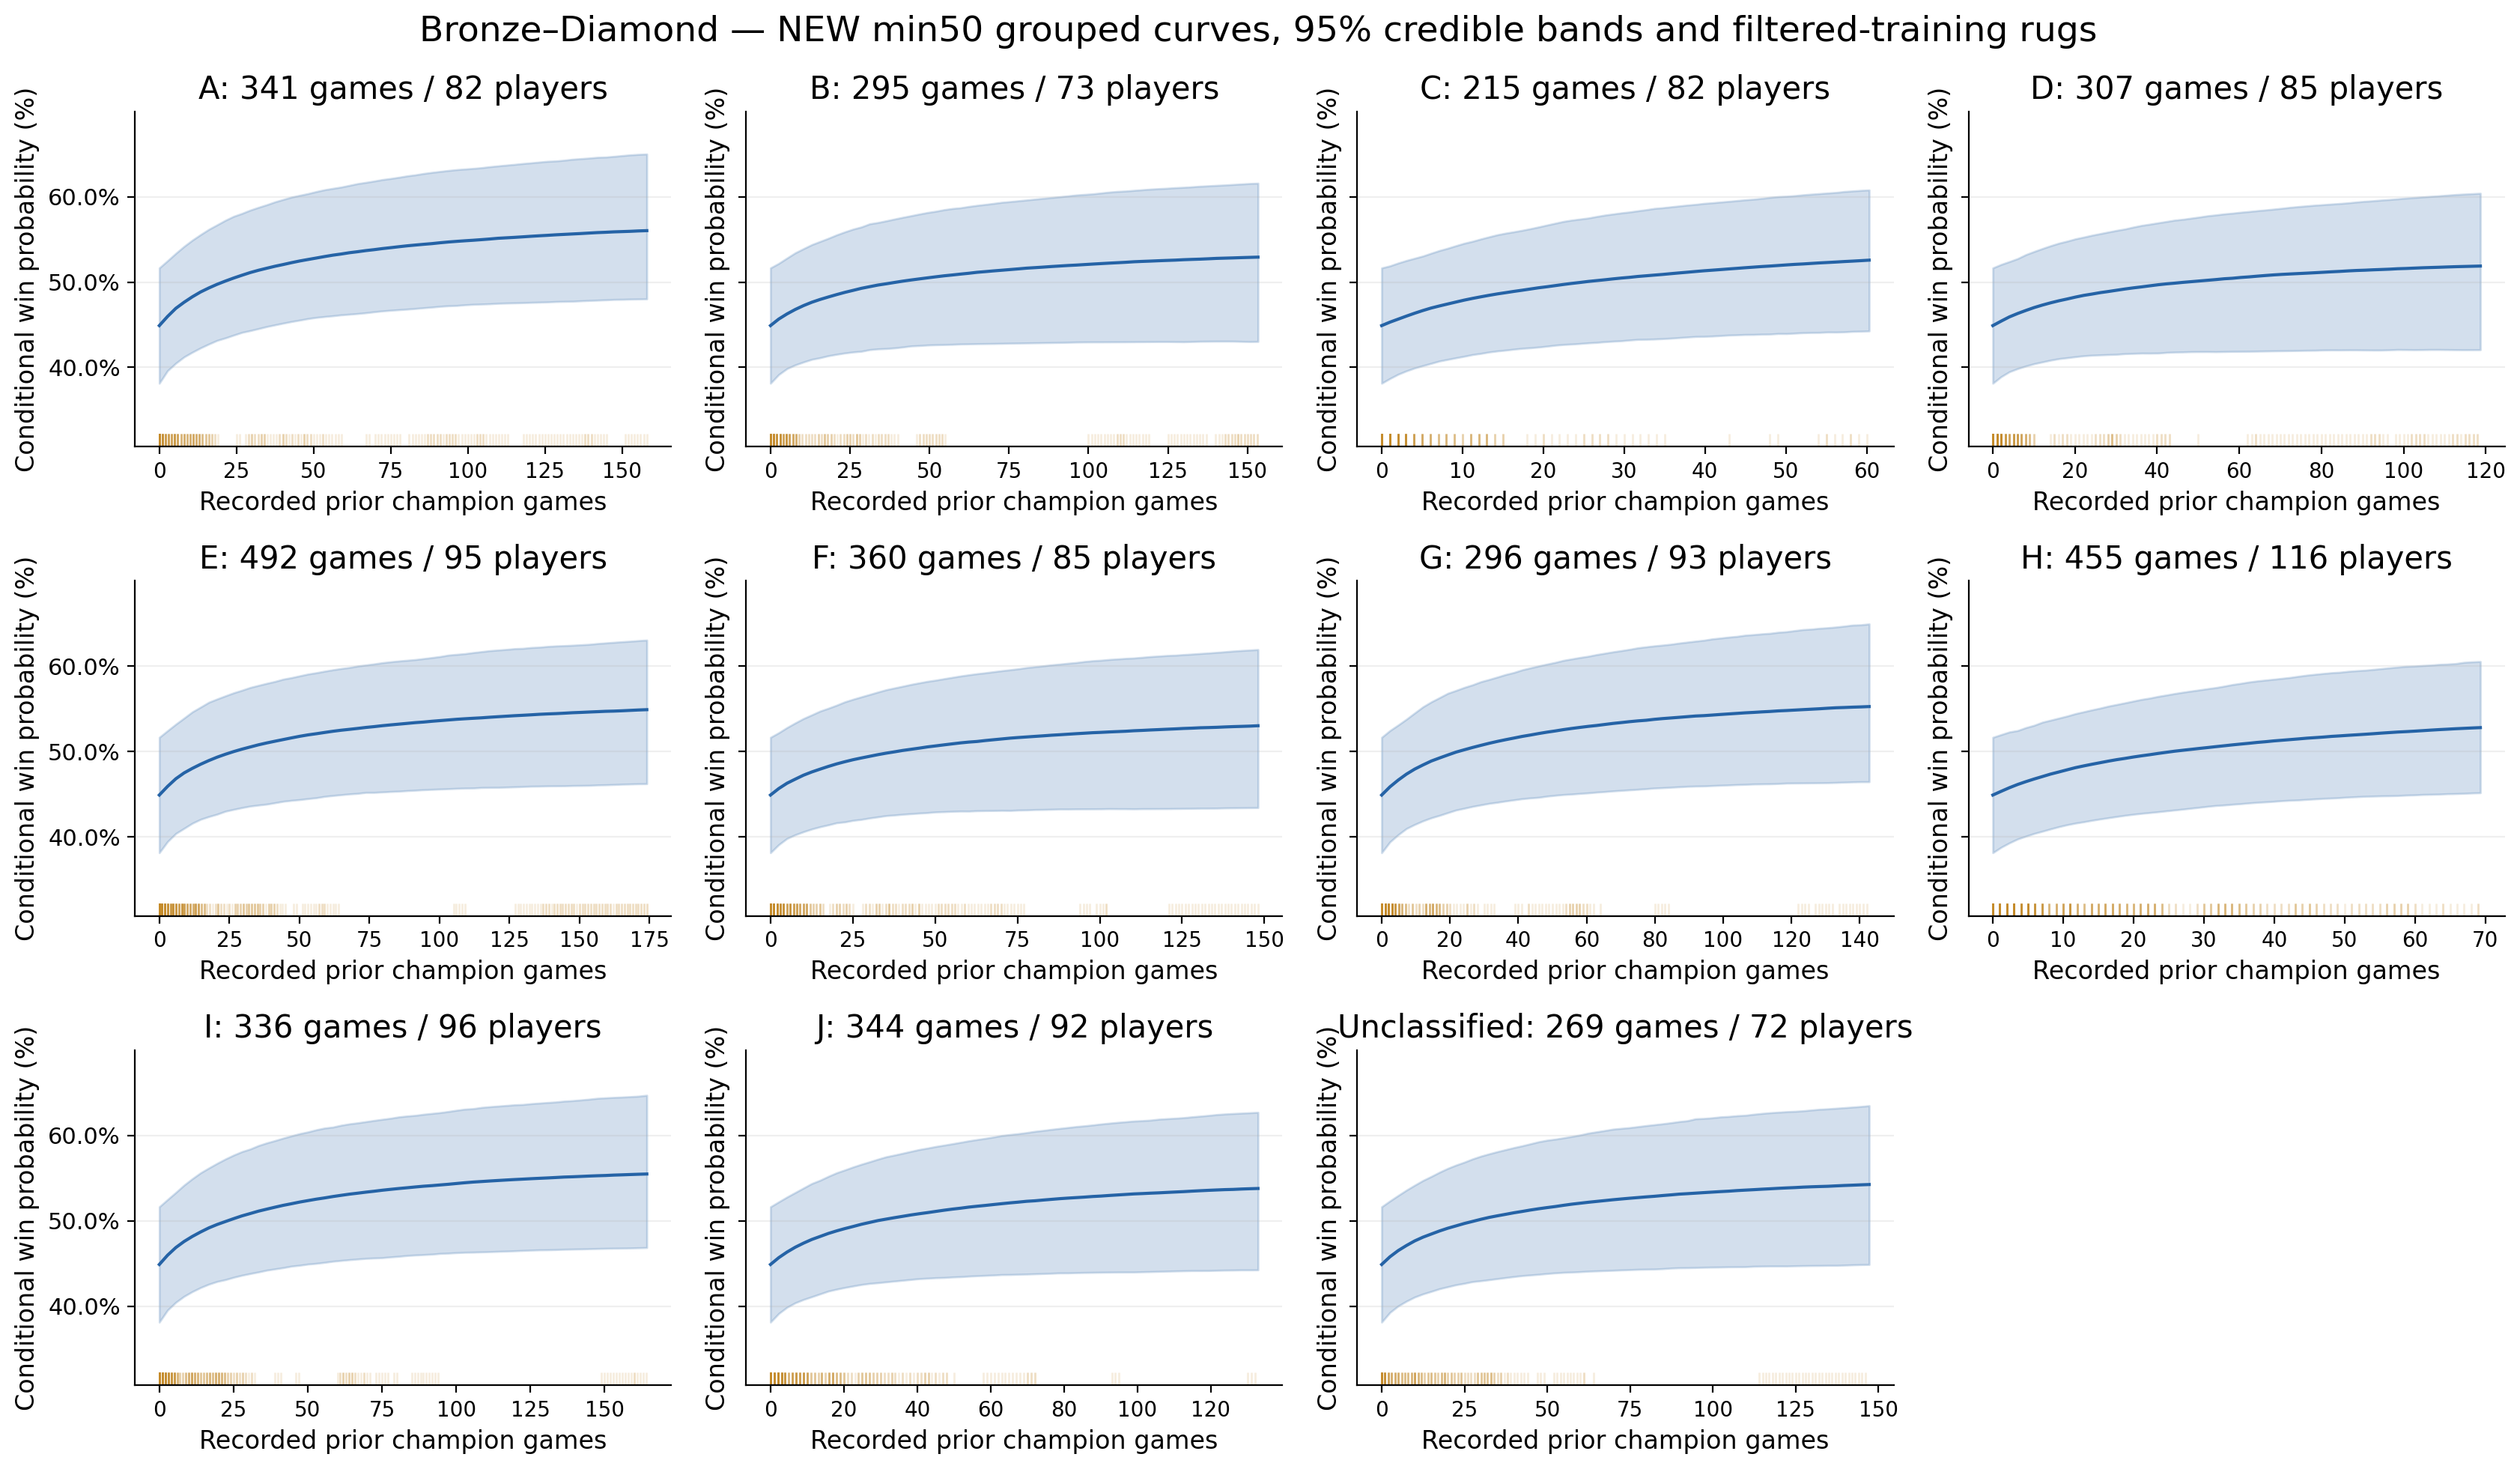

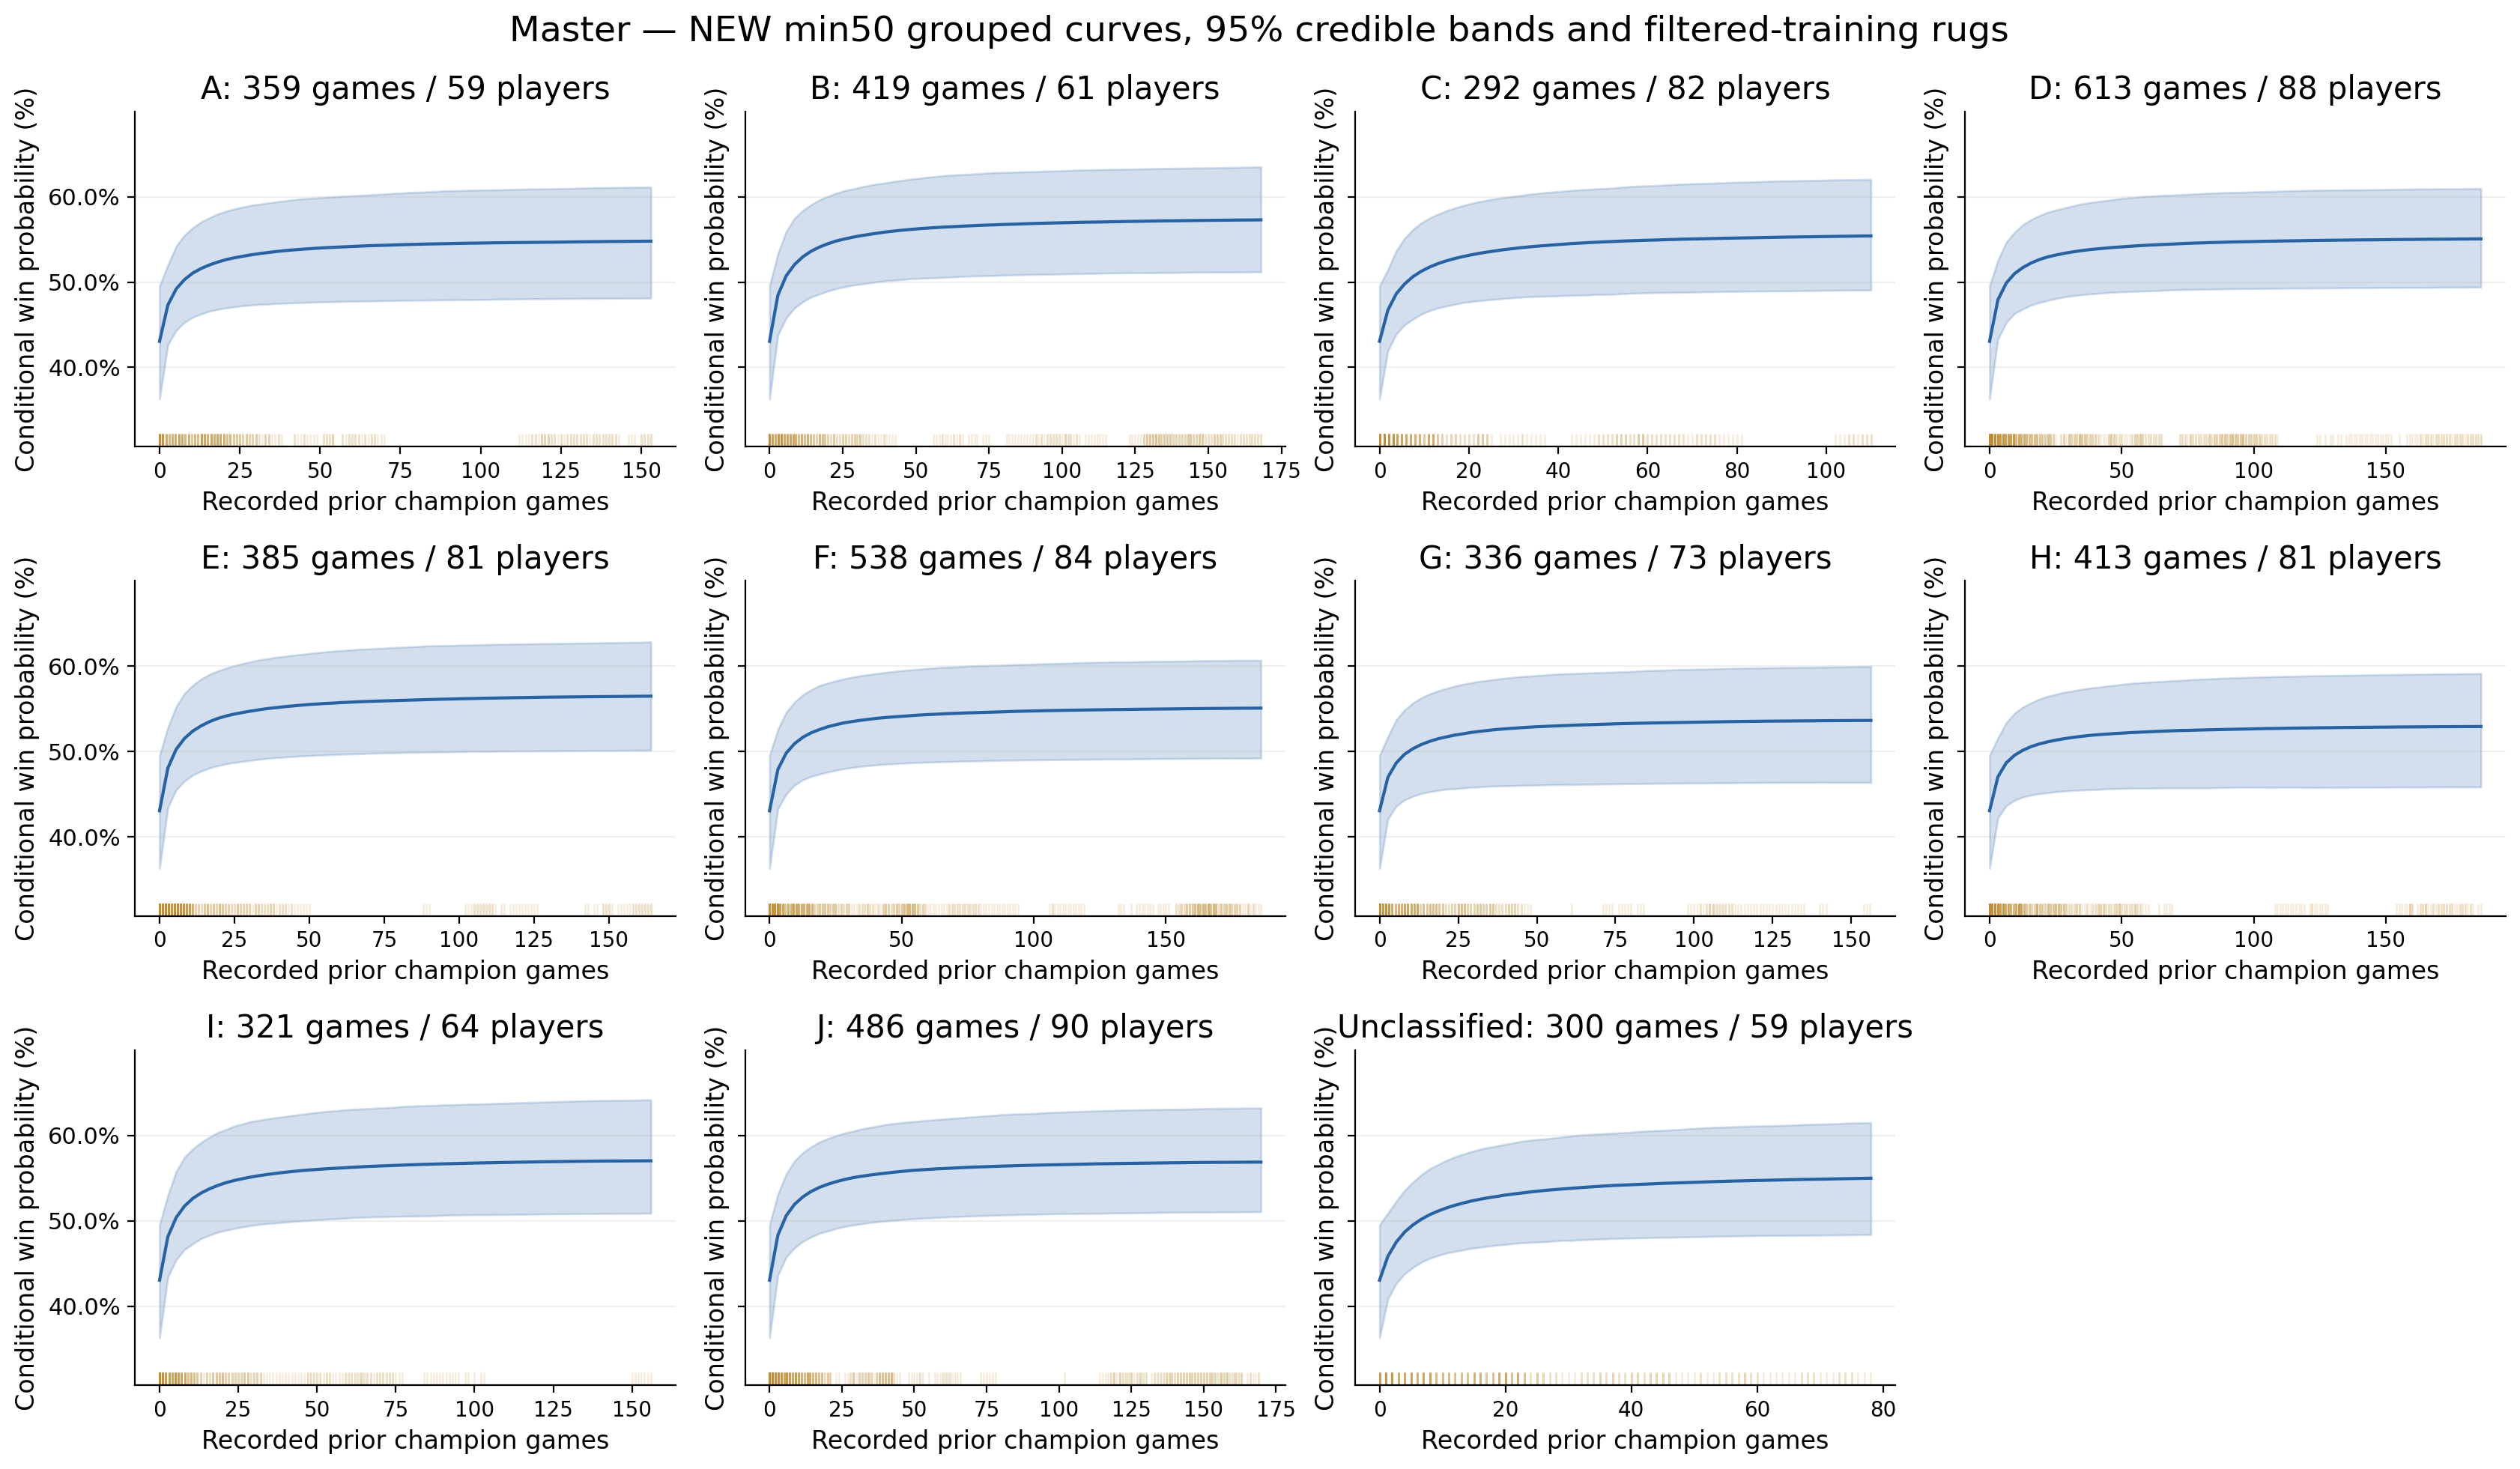

parameter,units,median,low_95,high_95,probability_positive
Intercept,Log-odds; centered continuous covariates; n=0; top/reference rank; zero identity effects,-0.185,-0.454,0.082,0.086
Raw matchup,Log-odds per filtered-training SD,0.120,0.046,0.190,1.000
log(1 + prior total games),Log-odds per filtered-training SD,-0.058,-0.134,0.018,0.068
"Historical champion WR Beta(1,1)",Log-odds per filtered-training SD,0.026,-0.043,0.095,0.783
Raw matchup: +2 percentage points,Log-odds per +0.02 raw matchup probability,0.060,0.023,0.096,1.000
jungle versus top,Log-odds contrast,0.074,-0.154,0.300,0.739
mid versus top,Log-odds contrast,0.148,-0.078,0.379,0.900
adc versus top,Log-odds contrast,0.078,-0.144,0.310,0.749
support versus top,Log-odds contrast,0.166,-0.061,0.398,0.920
SILVER versus Bronze,Log-odds contrast,0.046,-0.212,0.300,0.636


parameter,median,low_95,high_95,probability_positive
A,0.576,0.197,1.166,0.998
B,0.416,-0.021,0.959,0.969
C,0.519,0.065,1.173,0.985
D,0.386,-0.096,0.960,0.946
E,0.500,0.132,1.049,0.996
F,0.421,-0.011,0.958,0.972
G,0.542,0.155,1.164,0.995
H,0.507,0.091,1.121,0.991
I,0.539,0.148,1.152,0.995
J,0.474,0.049,1.053,0.982


parameter,units,median,low_95,high_95,probability_positive
Intercept,Log-odds; centered continuous covariates; n=0; top/reference rank; zero identity effects,-0.280,-0.564,-0.019,0.016
Raw matchup,Log-odds per filtered-training SD,0.149,0.089,0.212,1.000
log(1 + prior total games),Log-odds per filtered-training SD,-0.032,-0.099,0.035,0.170
"Historical champion WR Beta(1,1)",Log-odds per filtered-training SD,0.012,-0.051,0.072,0.639
Raw matchup: +2 percentage points,Log-odds per +0.02 raw matchup probability,0.078,0.046,0.110,1.000
jungle versus top,Log-odds contrast,0.000,-0.226,0.223,0.500
mid versus top,Log-odds contrast,-0.161,-0.371,0.041,0.068
adc versus top,Log-odds contrast,-0.058,-0.271,0.156,0.295
support versus top,Log-odds contrast,-0.173,-0.396,0.057,0.070
Experience amplitude,Asymptotic log-odds; common amplitude,0.521,0.270,0.782,1.000


parameter,median,low_95,high_95,probability_positive
A,0.496,0.138,0.802,0.996
B,0.599,0.290,0.915,1.000
C,0.528,0.181,0.864,0.998
D,0.505,0.189,0.804,0.998
E,0.567,0.237,0.890,0.998
F,0.503,0.207,0.787,1.000
G,0.447,0.090,0.762,0.989
H,0.413,0.054,0.718,0.987
I,0.593,0.275,0.934,1.000
J,0.583,0.267,0.910,1.000


Coefficients are log-odds, not win-probability percentage points. The common +2 raw matchup pp row equals β × .02 / the NEW training SD. Experience is b × n/(n+k); n is recorded prior champion games, and k is half-saturation in recorded games. k and SDs are exponentiated from their log parameters, with blank sign probabilities; posterior sign probabilities are not p-values. Shared uses one experience amplitude; grouped totals add the shared amplitude and the reconstructed zero-sum group deviation. The original priors/equations/group definitions are unchanged. No A–J ordering is imposed.

In [6]:
min50_plots.curves(MIN50_REFIT_DATA)
min50_plots.parameters(MIN50_REFIT_DATA,grouped=True)

## 6. Expanded recommendations from BOTH new posterior specifications

A selects highest raw matchup; B selects highest posterior mean separately by mode. Exact ties use the smallest champion ID. Counts are per actual-main-pick player-game, not pair-weighted.

Result,Master: 339 games,Bronze–Diamond: 264 games
Alternative has the higher mean prediction.,139 (41.0%),121 (45.8%)
Alternative favored: paired 95% interval above zero.,4 (1.2%),1 (0.4%)
Main favored: paired 95% interval below zero.,2 (0.6%),0 (0.0%)
Uncertain: paired interval includes zero.,333 (98.2%),263 (99.6%)


Result,Master: 339 games,Bronze–Diamond: 264 games
Alternative has the higher mean prediction.,202 (59.6%),140 (53.0%)
Alternative favored: paired 95% interval above zero.,7 (2.1%),1 (0.4%)
Main favored: paired 95% interval below zero.,1 (0.3%),0 (0.0%)
Uncertain: paired interval includes zero.,331 (97.6%),263 (99.6%)


Result,Master: 339 games,Bronze–Diamond: 264 games
Alternative has the higher mean prediction.,155 (45.7%),130 (49.2%)
Alternative favored: paired 95% interval above zero.,3 (0.9%),2 (0.8%)
Main favored: paired 95% interval below zero.,1 (0.3%),0 (0.0%)
Uncertain: paired interval includes zero.,335 (98.8%),262 (99.2%)


Result,Master: 339 games,Bronze–Diamond: 264 games
Alternative has the higher mean prediction.,206 (60.8%),143 (54.2%)
Alternative favored: paired 95% interval above zero.,9 (2.7%),2 (0.8%)
Main favored: paired 95% interval below zero.,2 (0.6%),0 (0.0%)
Uncertain: paired interval includes zero.,328 (96.8%),262 (99.2%)


The higher-mean row overlaps the three interval categories. Both choices require ≥50 verified external matchup games. Zero recorded experience and no prior same-role play remain eligible. Reference-player results are retained separately in the saved reports and do not represent population averages. Intervals are paired Bayesian credible intervals from the NEW fits; they omit external benchmark uncertainty and selection adjustment.

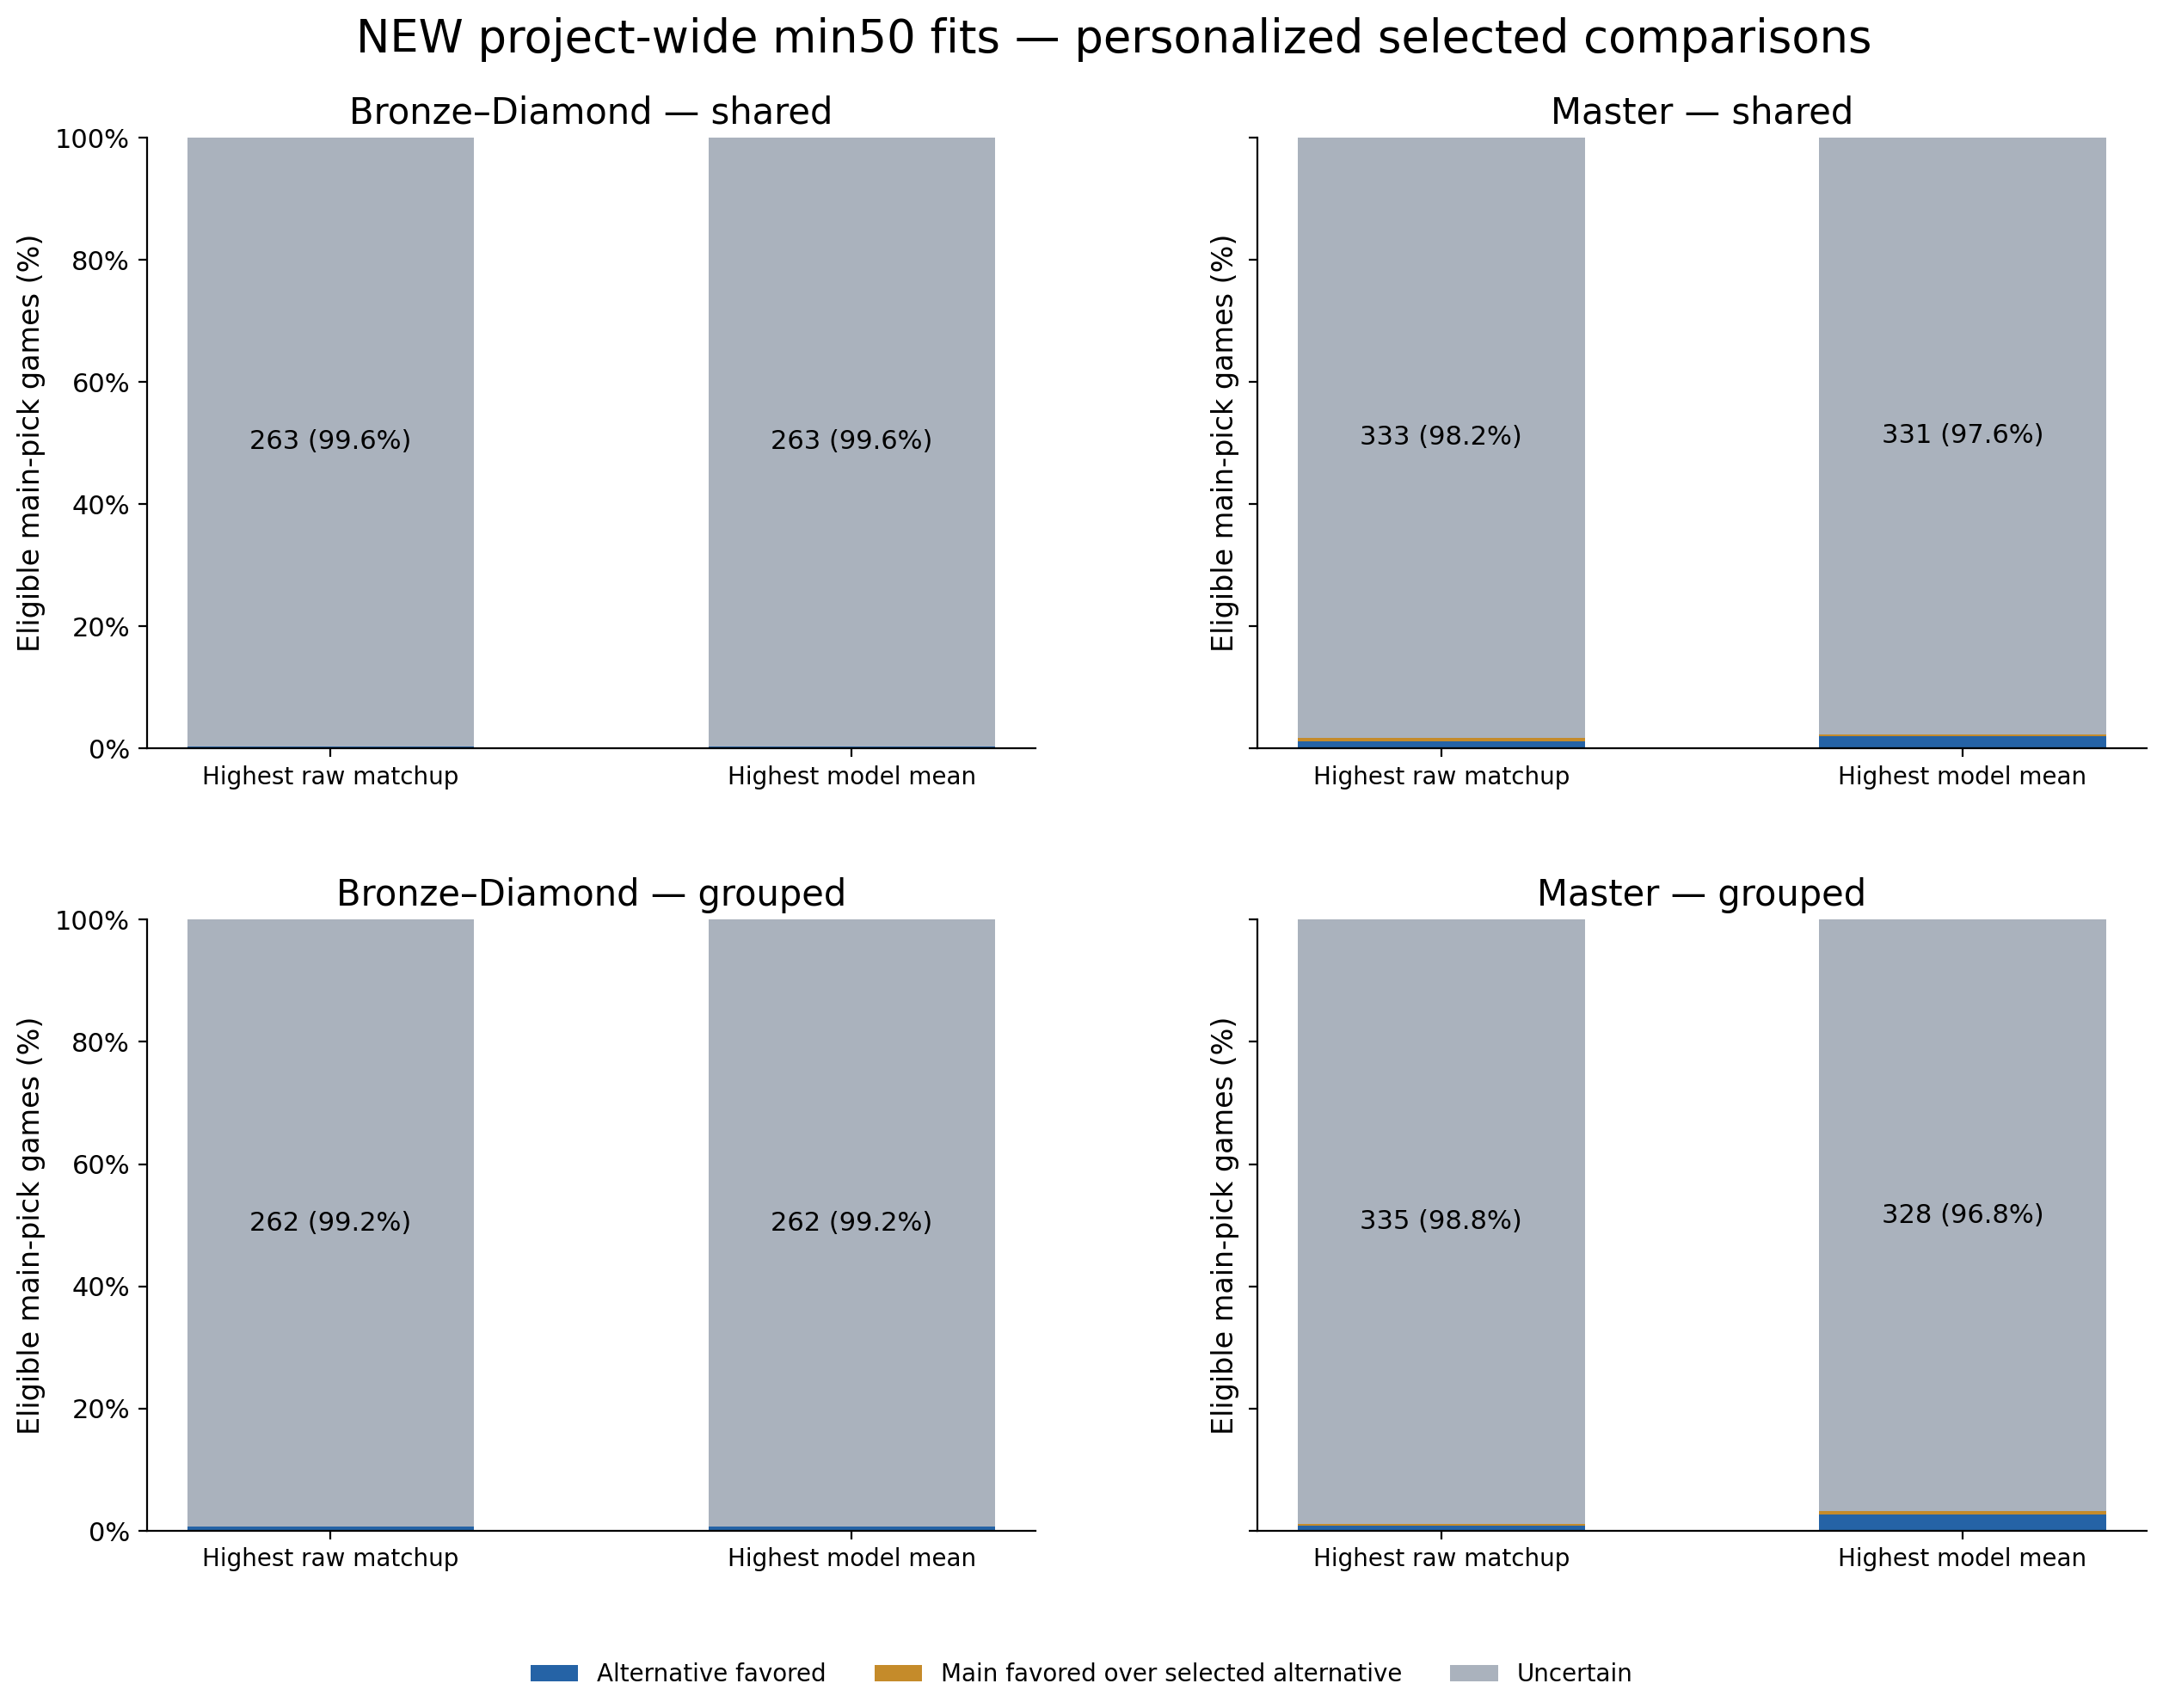

measure,count,denominator,players,unique_matches
Total actual main-pick games,288,288,87,288
Main-pick games with usable main features/benchmarks,264,288,87,264
Games with eligible published better-matchup alternatives,264,288,87,264
Usable main games without an eligible published alternative,0,288,0,0
external_matchup_games_below_50,24,288,10,24
No eligible published better-matchup alternative (not a confirmed main preference),0,288,0,0


selection_rule,mode,section,measure,count,denominator,percent,players
Best baseline matchup,Personalized,selected_experience,Zero recorded champion games,235,264,89.02%,84
Best baseline matchup,Personalized,selected_experience,"Champion history, no same-role history",18,264,6.82%,12
Best baseline matchup,Personalized,selected_experience,Prior same-role history,11,264,4.17%,9
Best model prediction,Personalized,selected_experience,Zero recorded champion games,167,264,63.26%,75
Best model prediction,Personalized,selected_experience,"Champion history, no same-role history",36,264,13.64%,20
Best model prediction,Personalized,selected_experience,Prior same-role history,61,264,23.11%,29
Best baseline matchup,Both modes,personalization_change,Stay-versus-leave point preference changed,15,264,5.68%,14
Best baseline matchup,Both modes,personalization_change,Selected alternative changed,0,264,0.00%,0
Best baseline matchup,Both modes,personalization_change,Interval classification changed,4,264,1.52%,4
Best model prediction,Both modes,personalization_change,Stay-versus-leave point preference changed,15,264,5.68%,14


#### Bronze–Diamond / NEW shared — actual saved examples (personalized; best baseline matchup)

**Zero-history alternative favored:** 2026-10-06 06:30 UTC, top, Hwei → Naafiri. Recorded champion games 12 → 0; raw matchup 36.54% → 66.07% (candidate benchmark n=56). Modeled win probability 40.00% → 58.54%; alternative − main **+18.54 pp [+1.06, +35.95]** (95% credible interval); **Alternative favored**.

**Main favored over zero-history alternative:** no example in these completed comparisons.

...

selection_rule,mode,section,measure,count,denominator,percent,players
Best baseline matchup,Personalized,selected_experience,Zero recorded champion games,298,339,87.91%,80
Best baseline matchup,Personalized,selected_experience,"Champion history, no same-role history",9,339,2.65%,7
Best baseline matchup,Personalized,selected_experience,Prior same-role history,32,339,9.44%,19
Best model prediction,Personalized,selected_experience,Zero recorded champion games,160,339,47.20%,54
Best model prediction,Personalized,selected_experience,"Champion history, no same-role history",25,339,7.37%,16
Best model prediction,Personalized,selected_experience,Prior same-role history,154,339,45.43%,61
Best baseline matchup,Both modes,personalization_change,Stay-versus-leave point preference changed,14,339,4.13%,11
Best baseline matchup,Both modes,personalization_change,Selected alternative changed,0,339,0.00%,0
Best baseline matchup,Both modes,personalization_change,Interval classification changed,6,339,1.77%,6
Best model prediction,Both modes,personalization_change,Stay-versus-leave point preference changed,9,339,2.65%,9


#### Master / NEW grouped — actual saved examples (personalized; best baseline matchup)

**Zero-history alternative favored:** 2026-10-06 02:31 UTC, adc, Samira → AurelionSol. Recorded champion games 97 → 0; raw matchup 44.14% → 76.36% (candidate benchmark n=55). Modeled win probability 47.88% → 66.42%; alternative − main **+18.54 pp [+1.64, +33.90]** (95% credible interval); **Alternative favored**.

**Main favored over zero-history alternative:** 2026-10-05 10:22 UTC, mid, Akshan → Leblanc. Recorded champion games 235 → 0; raw matchup 57.01% → 57.99% (candidate benchmark n=169). Modeled win probability 56.74% → 44.25%; alternative − main **-12.49 pp [-24.43, -1.18]** (95% credible interval); **Main favored over selected alternative**.

**Uncertain comparison:** 2026-10-05 01:32 UTC, adc, Caitlyn → Vladimir. Recorded champion games 114 → 0; raw matchup 52.13% → 63.64% (candidate benchmark n=55). Modeled win probability 53.99% → 51.78%; alternative − main **-2.21 pp [-15.87, +11.45]** (95% credible interval); **Uncertain**.

In [7]:
min50_plots.recommendations(MIN50_REFIT_DATA)

## 7. Interpretation, grouping comparison and limits

In [8]:
min50_plots.interpretation(MIN50_REFIT_DATA)

**Experience and matchup in the new shared fits:**

**Bronze–Diamond:** experience amplitude **0.459** (95% credible interval 0.192 to 0.853) log-odds; half-saturation **27.6 recorded games** (7.3 to 139.3). A +2 raw percentage-point matchup increase corresponds to **0.060** (0.023 to 0.096) log-odds. Both conditional associations are positive, while the wide k interval leaves the rate of saturation uncertain. These are not percentage-point changes in a player’s win probability or causal benefits of practice.

The filtered likelihood contains **1,369 player–champion combinations**, with median **1 fitted games** per combination; **75.7%** have at most two. This limited likelihood support remains distinct from the much longer recorded histories used for experience. The fitted identity-scale intervals and pooled unseen-combination uncertainty limit how precisely the model can personalize a comparison.

**Master:** experience amplitude **0.539** (95% credible interval 0.291 to 0.787) log-odds; half-saturation **4.4 recorded games** (1.4 to 18.7). A +2 raw percentage-point matchup increase corresponds to **0.077** (0.047 to 0.108) log-odds. Both conditional associations are positive, while the wide k interval leaves the rate of saturation uncertain. These are not percentage-point changes in a player’s win probability or causal benefits of practice.

The filtered likelihood contains **1,295 player–champion combinations**, with median **1 fitted games** per combination; **72.3%** have at most two. This limited likelihood support remains distinct from the much longer recorded histories used for experience. The fitted identity-scale intervals and pooled unseen-combination uncertainty limit how precisely the model can personalize a comparison.

...

shared, Best baseline matchup: alternative interval-favored in **4/339 (1.2%)**, uncertain **98.2%**; selected zero-history alternative **87.9%**; personalization changes staying/leaving **2.1%**.

shared, Best model prediction: alternative interval-favored in **7/339 (2.1%)**, uncertain **97.6%**; selected zero-history alternative **44.8%**; personalization changes staying/leaving **1.2%**.

grouped, Best baseline matchup: alternative interval-favored in **3/339 (0.9%)**, uncertain **98.8%**; selected zero-history alternative **87.9%**; personalization changes staying/leaving **4.1%**.

grouped, Best model prediction: alternative interval-favored in **9/339 (2.7%)**, uncertain **96.8%**; selected zero-history alternative **47.2%**; personalization changes staying/leaving **2.7%**.

Recorded games mean bounded collected Season 16 history, not lifetime practice. History events with low-support external benchmarks still contribute to experience, WR and main definitions. Sparse fitted player–champion likelihood support is distinct from long recorded histories. Learned identity effects and pooled unseen-identity uncertainty are retained in paired predictions. Stable chains and small predictive differences do not establish reliable pick advice. These retrospective conditional comparisons have unknown draft availability and unplayed outcomes; credible intervals omit external benchmark uncertainty and selection adjustment, and cannot establish causal switching benefits.